# 5. Final Model Evaluation and Error Analysis

This notebook evaluates the selected mammography classification models using a held-out test set.

The evaluation includes discrimination metrics, ROC and Precision–Recall curves, confusion matrices, bootstrap confidence intervals, systematic error analysis, and Grad-CAM visualizations.

Final model selection is based exclusively on validation data. The test set is reserved for the evaluation of the finalized configurations.

## 5.1	Experimental Setup and Checkpoints

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_DIR = PROJECT_DIR / "data"
SPLIT_DIR = DATA_DIR / "splits"
MODEL_DIR = PROJECT_DIR / "models"

RESULTS_DIR = PROJECT_DIR / "results" / "evaluation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Model directory:", MODEL_DIR)

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Model directory: c:\Users\Admin\Desktop\Projects\5_sem\DeepLearning\lab4\models


In [3]:
train_df = pd.read_csv(SPLIT_DIR / "train_pairs.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_pairs.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_pairs.csv")

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Breast pairs": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Class 0": [
        (df["target"] == 0).sum()
        for df in [train_df, val_df, test_df]
    ],
    "Class 1": [
        (df["target"] == 1).sum()
        for df in [train_df, val_df, test_df]
    ]
})

split_summary

,Split,Breast pairs,Class 0,Class 1
0,Train,1352,1014,338
1,Validation,1150,1093,57
2,Test,1907,1808,99


In [4]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    for view in ["CC", "MLO"]:
        paths = df[f"{view}_path"].map(
            lambda p: Path(p).is_file()
        )

        print(
            f"{name} {view}: "
            f"{paths.sum()}/{len(df)} images found"
        )

        assert paths.all(), f"Missing {view} images in {name}"

Train CC: 1352/1352 images found
Train MLO: 1352/1352 images found
Validation CC: 1150/1150 images found
Validation MLO: 1150/1150 images found
Test CC: 1907/1907 images found
Test MLO: 1907/1907 images found


In [5]:
train_ids = set(train_df["study_id"])
val_ids = set(val_df["study_id"])
test_ids = set(test_df["study_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("No study-level leakage detected.")

No study-level leakage detected.


The predefined data partitions are retained for final evaluation. Study-level overlap is excluded, and the held-out test set remains unused during model selection. The test distribution preserves the original class imbalance.

## 5.2	Final Model Selection and Repeated Runs

In [6]:
checkpoint_files = sorted(MODEL_DIR.glob("*.pth"))

print("Available checkpoints:", len(checkpoint_files))

for path in checkpoint_files:
    print(path.name)

Available checkpoints: 15
ablation_bce_best.pth
ablation_focal_best.pth
ablation_weighted_bce_best.pth
attention_head_controlled.pth
augmentation_augmentation_best.pth
augmentation_no_augmentation_best.pth
concat_head_controlled.pth
densenet121_CC_best.pth
efficientnet_b0_CC_best.pth
multiview_concat_frozen_best.pth
multiview_concat_partial_best.pth
resnet50_CC_best.pth
resnet50_MLO_best.pth
resolution_224_best.pth
resolution_512_best.pth


In [7]:
checkpoint_records = []

for path in checkpoint_files:

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    checkpoint_records.append({
        "Filename": path.name,
        "Architecture": checkpoint.get(
            "architecture",
            checkpoint.get("model_name")
        ),
        "Resolution": checkpoint.get(
            "resolution",
            checkpoint.get("image_size")
        ),
        "Loss": checkpoint.get(
            "loss",
            checkpoint.get("loss_name")
        ),
        "Seed": checkpoint.get("seed"),
        "Best epoch": checkpoint.get("best_epoch"),
        "Augmentation": checkpoint.get("augmentation"),
        "Fusion": checkpoint.get("fusion")
    })

checkpoint_df = pd.DataFrame(checkpoint_records)

display(checkpoint_df)

,Filename,Architecture,Resolution,Loss,Seed,Best epoch,Augmentation,Fusion
0,ablation_bce_best.pth,ResNet50,224.0,bce,42,3,None,NaN
1,ablation_focal_best.pth,ResNet50,224.0,focal,42,6,None,NaN
2,ablation_weighted_bce_best.pth,ResNet50,224.0,weighted_bce,42,3,None,NaN
3,attention_head_controlled.pth,NaN,NaN,NaN,42,9,None,attention
4,augmentation_augmentation_best.pth,ResNet50,512.0,Focal Loss,42,7,True,NaN
5,augmentation_no_augmentation_best.pth,ResNet50,512.0,Focal Loss,42,5,False,NaN
6,concat_head_controlled.pth,NaN,NaN,NaN,42,10,None,concatenation
7,densenet121_CC_best.pth,densenet121,224.0,NaN,42,8,None,NaN
8,efficientnet_b0_CC_best.pth,efficientnet_b0,224.0,NaN,42,2,None,NaN
9,multiview_concat_frozen_best.pth,multiview_resnet50,224.0,NaN,42,8,None,concatenation


In [8]:
result_files = sorted(
    (PROJECT_DIR / "results").rglob("*.csv")
)

for path in result_files:
    print(path.relative_to(PROJECT_DIR))

results\ablation\ablation_metric_changes.csv
results\ablation\augmentation_ablation_results.csv
results\ablation\final_ablation_summary.csv
results\ablation\loss_ablation_results.csv
results\ablation\resolution_224_history.csv
results\ablation\resolution_512_history.csv
results\ablation\resolution_ablation_results.csv
results\ablation\with_augmentation_history.csv
results\ablation\without_augmentation_history.csv
results\evaluation\final_training_results.csv
results\evaluation\final_training_results_backup.csv
results\evaluation\multi_view_seed10_history.csv
results\evaluation\multi_view_seed21_history.csv
results\evaluation\multi_view_seed42_history.csv
results\evaluation\predictions\multi_view_seed10_predictions.csv
results\evaluation\predictions\multi_view_seed21_predictions.csv
results\evaluation\predictions\multi_view_seed42_predictions.csv
results\evaluation\predictions\single_view_seed10_predictions.csv
results\evaluation\predictions\single_view_seed21_predictions.csv
results\ev

## 5.3 Final Model Training and Repeated Experiments

The final comparison evaluates single-view CC classification against two-view CC+MLO feature concatenation using ResNet50 encoders.

Both models use matched preprocessing, loss functions, data partitions, and optimization settings. However, the multi-view model contains two encoders and has a higher parameter count, which must be considered when interpreting performance differences.

Models are selected using validation data only, and the held-out test set remains reserved for final evaluation.

In [9]:
FINAL_SEEDS = [42, 10, 21]
FINAL_SIZE = 512
FINAL_EPOCHS = 10
FINAL_LR_ENCODER = 1e-5
FINAL_LR_HEAD = 1e-4

FINAL_BATCH_SIZE = 1
FINAL_ACCUM_STEPS = 8

FOCAL_ALPHA = 0.75
FOCAL_GAMMA = 2.0

In [10]:
class ResizeWithPadding:
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        image = image.copy()
        image.thumbnail(
            (self.size, self.size),
            Image.Resampling.BILINEAR
        )

        width, height = image.size

        padding = (
            (self.size - width) // 2,
            (self.size - height) // 2,
            self.size - width - (self.size - width) // 2,
            self.size - height - (self.size - height) // 2
        )

        return TF.pad(image, padding, fill=0)


final_transform = transforms.Compose([
    ResizeWithPadding(FINAL_SIZE),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [11]:
class FinalMammographyDataset(Dataset):

    def __init__(self, dataframe, multiview=False):
        self.df = dataframe.reset_index(drop=True)
        self.multiview = multiview

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["CC_path"]) as img:
            cc = final_transform(img.convert("RGB"))

        label = torch.tensor(
            row["target"],
            dtype=torch.float32
        )

        if not self.multiview:
            return cc, label

        with Image.open(row["MLO_path"]) as img:
            mlo = final_transform(img.convert("RGB"))

        return cc, mlo, label

In [12]:
class FinalMultiViewResNet50(nn.Module):

    def __init__(self):
        super().__init__()

        self.cc_encoder = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )
        self.mlo_encoder = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        feature_dim = self.cc_encoder.fc.in_features

        self.cc_encoder.fc = nn.Identity()
        self.mlo_encoder.fc = nn.Identity()

        self.classifier = nn.Sequential(
            nn.Linear(feature_dim * 2, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, cc, mlo):
        cc_features = self.cc_encoder(cc)
        mlo_features = self.mlo_encoder(mlo)

        combined = torch.cat(
            [cc_features, mlo_features],
            dim=1
        )

        return self.classifier(combined)

In [13]:
def create_final_model(multiview=False):

    if multiview:
        model = FinalMultiViewResNet50()
        encoders = [
            model.cc_encoder,
            model.mlo_encoder
        ]
        head = model.classifier

    else:
        model = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            1
        )

        encoders = [model]
        head = model.fc

    for parameter in model.parameters():
        parameter.requires_grad = False

    encoder_parameters = []

    for encoder in encoders:
        for parameter in encoder.layer4.parameters():
            parameter.requires_grad = True

        encoder_parameters.extend(
            encoder.layer4.parameters()
        )

    for parameter in head.parameters():
        parameter.requires_grad = True

    head_parameters = list(head.parameters())

    model = model.to(device)

    return model, encoder_parameters, head_parameters

In [14]:
class FocalLoss(nn.Module):

    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):

        bce = nn.functional.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="none"
        )

        pt = torch.exp(-bce)

        alpha_t = (
            self.alpha * targets
            + (1 - self.alpha) * (1 - targets)
        )

        return (
            alpha_t * (1 - pt) ** self.gamma * bce
        ).mean()

In [15]:
def create_final_loaders(multiview=False, seed=42):

    train_dataset = FinalMammographyDataset(
        train_df,
        multiview=multiview
    )

    val_dataset = FinalMammographyDataset(
        val_df,
        multiview=multiview
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=FINAL_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=FINAL_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    return train_loader, val_loader

In [16]:
def freeze_batchnorm(model):

    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

In [17]:
def train_final_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    multiview=False
):
    model.train()
    freeze_batchnorm(model)

    optimizer.zero_grad(set_to_none=True)

    running_loss = 0.0
    accumulated = 0

    for batch in loader:

        if multiview:
            cc, mlo, labels = batch
            cc = cc.to(device)
            mlo = mlo.to(device)
        else:
            cc, labels = batch
            cc = cc.to(device)

        labels = labels.to(device).unsqueeze(1)
        batch_size = len(labels)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = (
                model(cc, mlo)
                if multiview else model(cc)
            )

            loss = criterion(logits, labels)

        # Accumulate sample-weighted gradients
        scaler.scale(loss * batch_size).backward()

        running_loss += loss.item() * batch_size
        accumulated += batch_size

        if accumulated >= FINAL_ACCUM_STEPS:

            scaler.unscale_(optimizer)

            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.div_(accumulated)

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)
            accumulated = 0

    if accumulated > 0:

        scaler.unscale_(optimizer)

        for parameter in model.parameters():
            if parameter.grad is not None:
                parameter.grad.div_(accumulated)

        scaler.step(optimizer)
        scaler.update()

    return running_loss / len(loader.dataset)

In [18]:
def evaluate_final(model, loader, criterion, multiview=False):

    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probs = []

    with torch.inference_mode():

        for batch in loader:

            if multiview:
                cc, mlo, labels = batch
                cc = cc.to(device)
                mlo = mlo.to(device)
            else:
                cc, labels = batch
                cc = cc.to(device)

            labels = labels.to(device).unsqueeze(1)

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = (
                    model(cc, mlo)
                    if multiview else model(cc)
                )

                loss = criterion(logits, labels)

            probs = torch.sigmoid(logits.float())

            total_loss += loss.item() * len(labels)

            all_labels.extend(
                labels.cpu().numpy().ravel()
            )

            all_probs.extend(
                probs.cpu().numpy().ravel()
            )

    return (
        total_loss / len(loader.dataset),
        np.array(all_labels),
        np.array(all_probs)
    )

In [19]:
import gc

set_seed(42)

test_model, encoder_params, head_params = create_final_model(
    multiview=True
)

test_loader, _ = create_final_loaders(
    multiview=True,
    seed=42
)

test_criterion = FocalLoss(
    alpha=FOCAL_ALPHA,
    gamma=FOCAL_GAMMA
).to(device)

test_optimizer = torch.optim.Adam([
    {"params": encoder_params, "lr": FINAL_LR_ENCODER},
    {"params": head_params, "lr": FINAL_LR_HEAD}
])

test_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

test_model.train()
freeze_batchnorm(test_model)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

cc, mlo, labels = next(iter(test_loader))

cc = cc.to(device)
mlo = mlo.to(device)
labels = labels.to(device).unsqueeze(1)

test_optimizer.zero_grad(set_to_none=True)

with torch.autocast(
    device_type=device.type,
    enabled=(device.type == "cuda")
):
    logits = test_model(cc, mlo)
    loss = test_criterion(logits, labels)

test_scaler.scale(loss).backward()
test_scaler.step(test_optimizer)
test_scaler.update()

print("Output shape:", logits.shape)
print("Loss:", round(loss.item(), 6))
print("Optimizer step: successful")

if torch.cuda.is_available():
    print(
        "Peak VRAM:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )

Output shape: torch.Size([1, 1])
Loss: 0.048572
Optimizer step: successful
Peak VRAM: 0.66 GB


In [20]:
del test_model
del test_optimizer
del test_scaler
del test_loader
del encoder_params, head_params
del cc, mlo, labels, logits, loss

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("GPU test completed.")

GPU test completed.


In [21]:
import time

FINAL_MODEL_DIR = MODEL_DIR / "final"
FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

def run_final_experiment(multiview=False, seed=42, allow_existing_history=False):

    set_seed(seed)

    model_name = "multi_view" if multiview else "single_view"
    run_name = f"{model_name}_seed{seed}"

    checkpoint_path = FINAL_MODEL_DIR / f"{run_name}_best.pth"
    history_path = RESULTS_DIR / f"{run_name}_history.csv"

    # Prevent accidental overwriting of completed experiments
    if checkpoint_path.exists() or (history_path.exists() and not allow_existing_history):
        raise FileExistsError(
            f"Run {run_name} already exists. "
            "Use a new run name or archive previous results."
        )

    print(f"\nStarting: {run_name}")
    print(f"Resolution: {FINAL_SIZE}x{FINAL_SIZE}")

    train_loader, val_loader = create_final_loaders(
        multiview=multiview,
        seed=seed
    )

    model, encoder_params, head_params = create_final_model(
        multiview=multiview
    )

    criterion = FocalLoss(
        alpha=FOCAL_ALPHA,
        gamma=FOCAL_GAMMA
    ).to(device)

    optimizer = torch.optim.Adam([
        {
            "params": encoder_params,
            "lr": FINAL_LR_ENCODER
        },
        {
            "params": head_params,
            "lr": FINAL_LR_HEAD
        }
    ])

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    history = []
    best_auprc = -1.0
    best_epoch = None
    best_metrics = None

    try:
        for epoch in range(1, FINAL_EPOCHS + 1):

            start_time = time.perf_counter()

            train_loss = train_final_epoch(
                model=model,
                loader=train_loader,
                criterion=criterion,
                optimizer=optimizer,
                scaler=scaler,
                multiview=multiview
            )

            val_loss, labels, probabilities = evaluate_final(
                model=model,
                loader=val_loader,
                criterion=criterion,
                multiview=multiview
            )

            val_auroc = roc_auc_score(
                labels, probabilities
            )

            val_auprc = average_precision_score(
                labels, probabilities
            )

            predictions = (
                probabilities >= 0.5
            ).astype(int)

            sensitivity = recall_score(
                labels, predictions,
                zero_division=0
            )

            tn, fp, fn, tp = confusion_matrix(
                labels, predictions,
                labels=[0, 1]
            ).ravel()

            specificity = (
                tn / (tn + fp)
                if (tn + fp) > 0 else np.nan
            )

            f1 = f1_score(
                labels, predictions,
                zero_division=0
            )

            elapsed = time.perf_counter() - start_time

            epoch_result = {
                "Epoch": epoch,
                "Train loss": train_loss,
                "Val loss": val_loss,
                "AUROC": val_auroc,
                "AUPRC": val_auprc,
                "Sensitivity": sensitivity,
                "Specificity": specificity,
                "F1": f1,
                "Time (s)": elapsed
            }

            history.append(epoch_result)

            print(
                f"Epoch {epoch:02d}/{FINAL_EPOCHS} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val loss: {val_loss:.4f} | "
                f"AUROC: {val_auroc:.4f} | "
                f"AUPRC: {val_auprc:.4f} | "
                f"Time: {elapsed:.1f}s"
            )

            if val_auprc > best_auprc:

                best_auprc = float(val_auprc)
                best_epoch = epoch
                best_metrics = epoch_result.copy()

                torch.save({
                    "model_state_dict": model.state_dict(),
                    "architecture": model_name,
                    "seed": int(seed),
                    "best_epoch": int(best_epoch),
                    "val_auprc": best_auprc,
                    "image_size": FINAL_SIZE,
                    "loss_name": "focal",
                    "focal_alpha": FOCAL_ALPHA,
                    "focal_gamma": FOCAL_GAMMA,
                    "encoder_lr": FINAL_LR_ENCODER,
                    "head_lr": FINAL_LR_HEAD,
                    "physical_batch_size": FINAL_BATCH_SIZE,
                    "effective_batch_size": (
                        FINAL_BATCH_SIZE * FINAL_ACCUM_STEPS
                    ),
                    "optimizer": "Adam",
                    "augmentation": "None",
                    "pretraining": "ImageNet",
                    "finetuning": "layer4 + classifier",
                    "hardware": (
                        torch.cuda.get_device_name(0)
                        if device.type == "cuda" else "CPU"
                    )
                }, checkpoint_path)

                print("  New best checkpoint saved.")

            pd.DataFrame(history).to_csv(
                history_path,
                index=False
            )

    finally:
        del model, optimizer, scaler
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print(
        f"\nBest epoch: {best_epoch}, "
        f"Validation AUPRC: {best_auprc:.4f}"
    )

    return {
        "Model": model_name,
        "Seed": seed,
        "Best epoch": best_epoch,
        "AUROC": best_metrics["AUROC"],
        "AUPRC": best_metrics["AUPRC"],
        "Sensitivity": best_metrics["Sensitivity"],
        "Specificity": best_metrics["Specificity"],
        "F1": best_metrics["F1"],
        "Checkpoint": str(checkpoint_path)
    }

### Run or reuse the final seed experiments

The following cell trains missing single-view and multi-view final runs for seeds 42, 10, and 21. Completed runs are reused when both the checkpoint and a full ten-epoch history exist. If only a published history exists (as in a fresh clone), it is copied to `results/evaluation/preexisting_histories/` before retraining. Incomplete runs stop with an error so results are not silently mixed.


In [ ]:
# Train missing final models before reading their histories below.
completed_runs = []
new_runs = []

for multiview in [False, True]:
    model_name = "multi_view" if multiview else "single_view"

    for seed in FINAL_SEEDS:
        run_name = f"{model_name}_seed{seed}"
        checkpoint_path = FINAL_MODEL_DIR / f"{run_name}_best.pth"
        history_path = RESULTS_DIR / f"{run_name}_history.csv"

        checkpoint_exists = checkpoint_path.is_file()
        history_exists = history_path.is_file()

        if checkpoint_exists and history_exists:
            history = pd.read_csv(history_path)
            expected_epochs = list(range(1, FINAL_EPOCHS + 1))
            if "Epoch" not in history or history["Epoch"].tolist() != expected_epochs:
                raise RuntimeError(
                    f"Incomplete history for {run_name}: {history_path}. "
                    "Archive the incomplete checkpoint and history before rerunning."
                )
            print(f"Reusing completed run: {run_name}")
            completed_runs.append(run_name)
            continue

        if checkpoint_exists:
            raise RuntimeError(
                f"Checkpoint exists without history for {run_name}. "
                "Archive the incomplete checkpoint before rerunning."
            )

        if history_exists:
            history = pd.read_csv(history_path)
            expected_epochs = list(range(1, FINAL_EPOCHS + 1))
            if "Epoch" not in history or history["Epoch"].tolist() != expected_epochs:
                raise RuntimeError(
                    f"Incomplete history for {run_name}: {history_path}. "
                    "Archive the incomplete history before rerunning."
                )

            # The repository includes histories but ignores large checkpoints.
            # Keep the published history before a fresh training run replaces it.
            import shutil

            archive_dir = RESULTS_DIR / "preexisting_histories"
            archive_dir.mkdir(exist_ok=True)
            archive_path = archive_dir / history_path.name
            if archive_path.exists():
                raise FileExistsError(f"History backup already exists: {archive_path}")
            shutil.copy2(history_path, archive_path)
            print(f"Preserved published history: {archive_path}")

        result = run_final_experiment(
            multiview=multiview,
            seed=seed,
            allow_existing_history=history_exists,
        )
        new_runs.append(result)

print(f"Reused {len(completed_runs)} runs; trained {len(new_runs)} runs.")

In [22]:
single_view_42 = pd.read_csv(
    RESULTS_DIR / "single_view_seed42_history.csv"
)

best_single = single_view_42.loc[
    single_view_42["AUPRC"].idxmax()
]

display(best_single.to_frame().T.round(4))

,Epoch,Train loss,Val loss,AUROC,AUPRC,Sensitivity,Specificity,F1,Time (s)
9,10.0,0.0001,0.0594,0.8368,0.3735,0.5965,0.8948,0.3301,83.6603


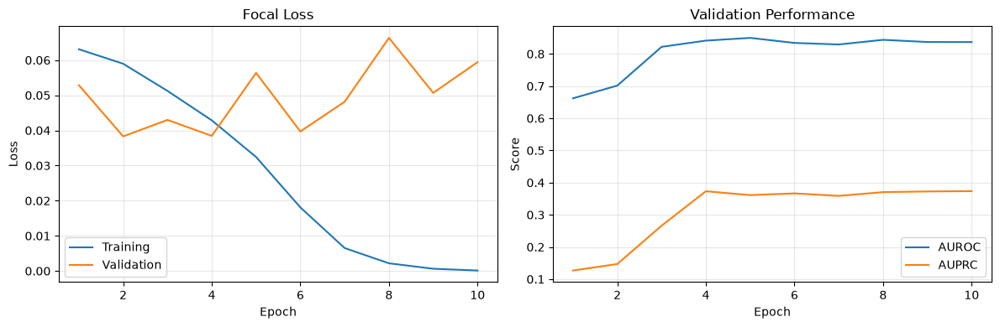

In [23]:
history = pd.read_csv(
    RESULTS_DIR / "single_view_seed42_history.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history["Epoch"],
    history["Train loss"],
    label="Training"
)

axes[0].plot(
    history["Epoch"],
    history["Val loss"],
    label="Validation"
)

axes[0].set_title("Focal Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history["Epoch"],
    history["AUROC"],
    label="AUROC"
)

axes[1].plot(
    history["Epoch"],
    history["AUPRC"],
    label="AUPRC"
)

axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Single-view Training Results

The single-view ResNet50 achieved a validation AUROC of 0.8368 and AUPRC of 0.3735, with sensitivity of 0.5965 and F1-score of 0.3301 at a decision threshold of 0.5.

Training loss approached zero, while validation loss fluctuated across epochs, indicating overfitting. The highest validation AUPRC was achieved at epoch 10, although its improvement over epoch 4 was marginal.

The model checkpoint was selected using validation AUPRC without accessing test-set performance.

In [24]:
multi_view_42 = pd.read_csv(
    RESULTS_DIR / "multi_view_seed42_history.csv"
)

best_multi = multi_view_42.loc[
    multi_view_42["AUPRC"].idxmax()
]

display(best_multi.to_frame().T.round(4))

,Epoch,Train loss,Val loss,AUROC,AUPRC,Sensitivity,Specificity,F1,Time (s)
3,4.0,0.0287,0.0309,0.8398,0.4091,0.5614,0.85,0.253,172.8402


### Single-view vs Multi-view Comparison

At seed 42, the multi-view ResNet50 achieved a validation AUROC of 0.8398 and AUPRC of 0.4091, compared with 0.8368 and 0.3735 for the single-view model.

Multi-view fusion improved AUPRC by 0.0356, suggesting a potential benefit from combining CC and MLO information. However, sensitivity, specificity, and F1-score at the default threshold of 0.5 were lower for the multi-view model.

The multi-view model achieved its highest AUPRC at epoch 4, after which validation performance gradually declined despite continued reductions in training loss. This indicates overfitting.

As these findings are based on a single random seed, repeated experiments are required before drawing conclusions about the stability of the observed improvement.

In [25]:
records = []

for model_name in ["single_view", "multi_view"]:
    for seed in [42, 10, 21]:

        run_name = f"{model_name}_seed{seed}"

        history_path = (
            RESULTS_DIR / f"{run_name}_history.csv"
        )

        checkpoint_path = (
            FINAL_MODEL_DIR / f"{run_name}_best.pth"
        )

        assert history_path.exists(), (
            f"Missing history: {history_path}"
        )

        assert checkpoint_path.exists(), (
            f"Missing checkpoint: {checkpoint_path}"
        )

        history = pd.read_csv(history_path)

        best_row = history.loc[
            history["AUPRC"].idxmax()
        ]

        records.append({
            "Model": model_name,
            "Seed": seed,
            "Best epoch": int(best_row["Epoch"]),
            "AUROC": float(best_row["AUROC"]),
            "AUPRC": float(best_row["AUPRC"]),
            "Sensitivity": float(best_row["Sensitivity"]),
            "Specificity": float(best_row["Specificity"]),
            "F1": float(best_row["F1"]),
            "Checkpoint": str(checkpoint_path)
        })

final_results = pd.DataFrame(records)

display(final_results.round(4))

,Model,Seed,Best epoch,AUROC,AUPRC,Sensitivity,Specificity,F1,Checkpoint
0,single_view,42,10,0.8368,0.3735,0.5965,0.8948,0.3301,c:\Users\Admin\Desktop\Projects\5_sem\DeepLear...
1,single_view,10,5,0.8194,0.3574,0.5789,0.8801,0.2986,c:\Users\Admin\Desktop\Projects\5_sem\DeepLear...
2,single_view,21,7,0.8453,0.4049,0.6140,0.8683,0.2966,c:\Users\Admin\Desktop\Projects\5_sem\DeepLear...
3,multi_view,42,4,0.8398,0.4091,0.5614,0.8500,0.2530,c:\Users\Admin\Desktop\Projects\5_sem\DeepLear...
4,multi_view,10,5,0.8076,0.3923,0.6667,0.8280,0.2686,c:\Users\Admin\Desktop\Projects\5_sem\DeepLear...
5,multi_view,21,7,0.8206,0.4417,0.4561,0.9552,0.3939,c:\Users\Admin\Desktop\Projects\5_sem\DeepLear...


In [26]:
assert len(final_results) == 6

assert (
    final_results.groupby(["Model", "Seed"]).size() == 1
).all()

csv_path = RESULTS_DIR / "final_training_results.csv"

# Back up the old CSV before replacing it
if csv_path.exists():
    import shutil

    shutil.copy2(
        csv_path,
        RESULTS_DIR / "final_training_results_backup.csv"
    )

final_results.to_csv(
    csv_path,
    index=False
)

print("All 6 experiment results restored and saved.")

All 6 experiment results restored and saved.


### Repeated Experiments Summary

The single-view and multi-view models were trained independently using three random seeds (10, 21, and 42). The best checkpoint for each run was selected according to validation AUPRC.

Multi-view classification achieved higher validation AUPRC for all three seeds, with a mean improvement of approximately 0.0358. However, the single-view model achieved higher mean AUROC, while the multi-view model exhibited greater variability in sensitivity and F1-score.

These findings suggest that combining CC and MLO views may improve precision–recall discrimination, although the benefit does not extend consistently to all evaluation metrics.

In [27]:
final_results = pd.read_csv(
    RESULTS_DIR / "final_training_results.csv"
)

metrics = [
    "AUROC",
    "AUPRC",
    "Sensitivity",
    "Specificity",
    "F1"
]

summary = (
    final_results
    .groupby("Model")[metrics]
    .agg(["mean", "std"])
)

display(summary.round(4))

summary.to_csv(
    RESULTS_DIR / "repeated_experiments_summary.csv"
)

AUROC           AUPRC         Sensitivity         Specificity  \
               mean     std    mean     std        mean     std        mean   
Model                                                                         
multi_view   0.8227  0.0162  0.4144  0.0251      0.5614  0.1053      0.8777   
single_view  0.8338  0.0132  0.3786  0.0241      0.5965  0.0175      0.8811   

                         F1          
                std    mean     std  
Model                                
multi_view   0.0680  0.3052  0.0773  
single_view  0.0133  0.3084  0.0188

In [28]:
paired_auprc = final_results.pivot(
    index="Seed",
    columns="Model",
    values="AUPRC"
)

paired_auprc["Difference"] = (
    paired_auprc["multi_view"]
    - paired_auprc["single_view"]
)

display(paired_auprc.round(4))

print(
    "Mean AUPRC improvement:",
    round(paired_auprc["Difference"].mean(), 4)
)

Model,multi_view,single_view,Difference
Seed,,,
10,0.3923,0.3574,0.0349
21,0.4417,0.4049,0.0369
42,0.4091,0.3735,0.0356


Mean AUPRC improvement: 0.0358


## 5.4	ROC and Precision–Recall Curves

The six previously trained models are evaluated on the independent test set without further training or checkpoint selection.

Three independently seeded checkpoints are evaluated for each architecture. Test predictions are used to calculate AUROC, AUPRC, sensitivity, specificity, precision, and F1-score. The default classification threshold of 0.5 is retained for threshold-dependent metrics.

Results are aggregated across seeds to assess the consistency of model performance

In [29]:
test_single_dataset = FinalMammographyDataset(
    test_df,
    multiview=False
)

test_multi_dataset = FinalMammographyDataset(
    test_df,
    multiview=True
)

test_single_loader = DataLoader(
    test_single_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_multi_loader = DataLoader(
    test_multi_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Single-view test samples:", len(test_single_dataset))
print("Multi-view test samples:", len(test_multi_dataset))

Single-view test samples: 1907
Multi-view test samples: 1907


Each model is reconstructed using its original architecture and loaded from the corresponding saved checkpoint. All parameters are kept unchanged during test evaluation.

In [30]:
def load_final_checkpoint(model_name, seed):

    multiview = (model_name == "multi_view")

    checkpoint_path = (
        FINAL_MODEL_DIR
        / f"{model_name}_seed{seed}_best.pth"
    )

    assert checkpoint_path.exists(), (
        f"Checkpoint not found: {checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model, _, _ = create_final_model(
        multiview=multiview
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    return model

In [31]:
def predict_on_test(model, loader, multiview=False):

    model.eval()

    all_labels = []
    all_probabilities = []

    with torch.inference_mode():

        for batch in loader:

            if multiview:
                cc, mlo, labels = batch

                cc = cc.to(device)
                mlo = mlo.to(device)

            else:
                cc, labels = batch
                cc = cc.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = (
                    model(cc, mlo)
                    if multiview
                    else model(cc)
                )

            probabilities = torch.sigmoid(
                logits.float()
            ).cpu().numpy().ravel()

            all_labels.extend(
                labels.numpy().ravel()
            )

            all_probabilities.extend(probabilities)

    return (
        np.asarray(all_labels, dtype=int),
        np.asarray(all_probabilities, dtype=float)
    )

In [32]:
def calculate_test_metrics(labels, probabilities, threshold=0.5):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0 else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else np.nan
    )

    return {
        "AUROC": roc_auc_score(labels, probabilities),
        "AUPRC": average_precision_score(labels, probabilities),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "F1": f1_score(
            labels, predictions, zero_division=0
        )
    }

In [37]:
test_results = []

PREDICTIONS_DIR = RESULTS_DIR / "predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

for model_name in ["single_view", "multi_view"]:

    multiview = (model_name == "multi_view")

    loader = (
        test_multi_loader
        if multiview
        else test_single_loader
    )

    for seed in [42, 10, 21]:

        print(f"Evaluating {model_name}, seed {seed}...")

        model = load_final_checkpoint(
            model_name=model_name,
            seed=seed
        )

        labels, probabilities = predict_on_test(
            model,
            loader,
            multiview=multiview
        )

        assert len(labels) == len(test_df)
        assert np.array_equal(
            labels,
            test_df["target"].to_numpy(dtype=int)
        )

        metrics = calculate_test_metrics(
            labels,
            probabilities
        )

        test_results.append({
            "Model": model_name,
            "Seed": seed,
            **metrics
        })

        predictions_df = test_df.copy()

        predictions_df["Probability"] = probabilities
        predictions_df["Prediction"] = (
            probabilities >= 0.5
        ).astype(int)

        predictions_df.to_csv(
            PREDICTIONS_DIR
            / f"{model_name}_seed{seed}_predictions.csv",
            index=False
        )

        pd.DataFrame(test_results).to_csv(
            RESULTS_DIR / "test_metrics.csv",
            index=False
        )

        print(
            f"AUROC: {metrics['AUROC']:.4f} | "
            f"AUPRC: {metrics['AUPRC']:.4f} | "
            f"F1: {metrics['F1']:.4f}"
        )

        del model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

Evaluating single_view, seed 42...
AUROC: 0.7860 | AUPRC: 0.4067 | F1: 0.3115
Evaluating single_view, seed 10...
AUROC: 0.7798 | AUPRC: 0.4238 | F1: 0.3095
Evaluating single_view, seed 21...
AUROC: 0.7980 | AUPRC: 0.4614 | F1: 0.3090
Evaluating multi_view, seed 42...
AUROC: 0.8041 | AUPRC: 0.4621 | F1: 0.3053
Evaluating multi_view, seed 10...
AUROC: 0.7925 | AUPRC: 0.4567 | F1: 0.2691
Evaluating multi_view, seed 21...
AUROC: 0.8049 | AUPRC: 0.4477 | F1: 0.4239


,Model,Seed,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,single_view,42,0.7860,0.4067,0.5051,0.9049,0.2252,0.3115
1,single_view,10,0.7798,0.4238,0.5253,0.8977,0.2194,0.3095
2,single_view,21,0.7980,0.4614,0.5556,0.8883,0.2140,0.3090
3,multi_view,42,0.8041,0.4621,0.5859,0.8767,0.2064,0.3053
4,multi_view,10,0.7925,0.4567,0.5859,0.8485,0.1747,0.2691
5,multi_view,21,0.8049,0.4477,0.3939,0.9746,0.4588,0.4239


### Test Classification Results

All six models were successfully evaluated on 1,907 breast-level test samples, including 99 positive cases.

The multi-view models achieved higher AUPRC than the corresponding single-view models for seeds 10 and 42, but not for seed 21. These findings indicate that the advantage observed consistently on validation data was less stable on the independent test set.

The results also demonstrate substantial differences in threshold-dependent metrics, particularly sensitivity and F1-score, across multi-view training runs.

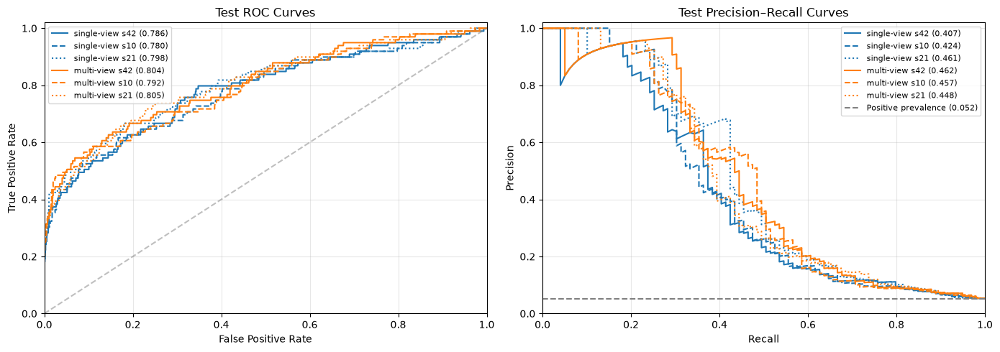

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {
    "single_view": "tab:blue",
    "multi_view": "tab:orange"
}

linestyles = {
    42: "-",
    10: "--",
    21: ":"
}

for model_name in ["single_view", "multi_view"]:
    for seed in [42, 10, 21]:

        predictions_df = pd.read_csv(
            PREDICTIONS_DIR
            / f"{model_name}_seed{seed}_predictions.csv"
        )

        labels = predictions_df["target"].to_numpy()
        probabilities = predictions_df["Probability"].to_numpy()

        fpr, tpr, _ = roc_curve(
            labels, probabilities
        )

        precision, recall, _ = precision_recall_curve(
            labels, probabilities
        )

        auroc = roc_auc_score(labels, probabilities)
        auprc = average_precision_score(labels, probabilities)

        display_name = model_name.replace("_", "-")

        axes[0].plot(
            fpr,
            tpr,
            color=colors[model_name],
            linestyle=linestyles[seed],
            label=f"{display_name} s{seed} ({auroc:.3f})"
        )

        axes[1].plot(
            recall,
            precision,
            color=colors[model_name],
            linestyle=linestyles[seed],
            label=f"{display_name} s{seed} ({auprc:.3f})"
        )

axes[0].plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    alpha=0.5
)

positive_prevalence = test_df["target"].mean()

axes[1].axhline(
    positive_prevalence,
    color="gray",
    linestyle="--",
    label=f"Positive prevalence ({positive_prevalence:.3f})"
)

axes[0].set_title("Test ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

axes[1].set_title("Test Precision–Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "test_roc_pr_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### ROC and Precision–Recall Analysis

The ROC and Precision–Recall curves show that both architectures provide meaningful discrimination between low-suspicion and suspicious breast cases.

Multi-view models generally achieved stronger Precision–Recall performance, although the advantage varied across seeds. The curves also illustrate the importance of evaluating performance across decision thresholds rather than relying exclusively on predictions obtained at a threshold of 0.5.

In [43]:
test_metrics = pd.read_csv(
    RESULTS_DIR / "test_metrics.csv"
)

metric_columns = [
    "AUROC",
    "AUPRC",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1"
]

test_summary = (
    test_metrics
    .groupby("Model")[metric_columns]
    .agg(["mean", "std"])
)

display(test_summary.round(4))

test_summary.to_csv(
    RESULTS_DIR / "test_summary.csv"
)

AUROC           AUPRC         Sensitivity         Specificity  \
               mean     std    mean     std        mean     std        mean   
Model                                                                         
multi_view   0.8005  0.0070  0.4555  0.0072      0.5219  0.1108      0.8999   
single_view  0.7880  0.0093  0.4307  0.0279      0.5286  0.0254      0.8969   

                    Precision              F1          
                std      mean     std    mean     std  
Model                                                  
multi_view   0.0662    0.2800  0.1557  0.3328  0.0810  
single_view  0.0083    0.2195  0.0056  0.3100  0.0013

In [44]:
paired_test_auprc = test_metrics.pivot(
    index="Seed",
    columns="Model",
    values="AUPRC"
)

paired_test_auprc["Difference"] = (
    paired_test_auprc["multi_view"]
    - paired_test_auprc["single_view"]
)

display(paired_test_auprc.round(4))

print(
    "Mean test AUPRC difference:",
    round(paired_test_auprc["Difference"].mean(), 4)
)

Model,multi_view,single_view,Difference
Seed,,,
10,0.4567,0.4238,0.0328
21,0.4477,0.4614,-0.0136
42,0.4621,0.4067,0.0553


Mean test AUPRC difference: 0.0248


### Test Performance Summary

Across three random seeds, the multi-view ResNet50 achieved a mean test AUROC of 0.8005 ± 0.0070 and AUPRC of 0.4555 ± 0.0072, compared with 0.7880 ± 0.0093 and 0.4307 ± 0.0279 for the single-view model.

The mean AUPRC improvement was 0.0248. However, this advantage was observed in only two of the three paired seed comparisons, suggesting that the benefit of multi-view fusion is not fully consistent across independent training runs.

Although multi-view classification achieved a higher mean F1-score (0.3328 versus 0.3100), it also showed substantially greater variability (0.0810 versus 0.0013).

Overall, the findings suggest a modest potential benefit from combining CC and MLO views, but do not establish consistently superior performance across all metrics or random seeds.

## 5.5	Confusion Matrices and Confidence Intervals

The single-view and multi-view models trained with seed 42 are presented as representative examples, selected independently of their test performance. All predictions use the predefined classification threshold of 0.5.

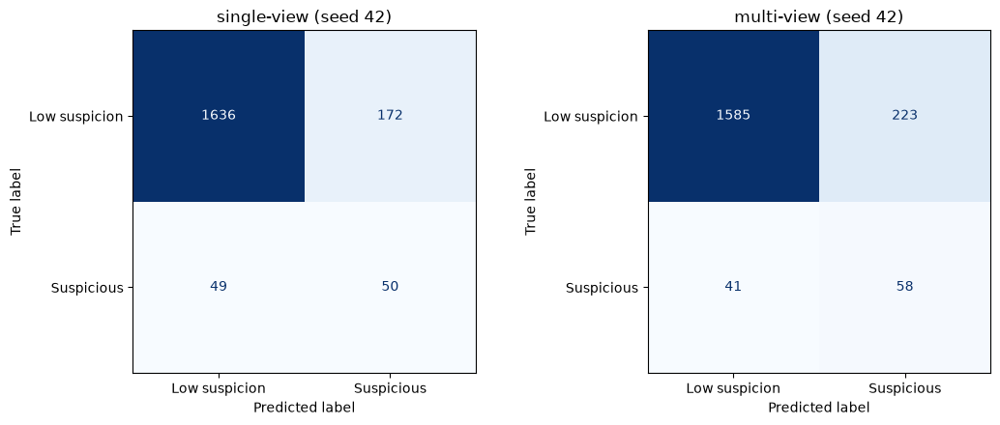

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, model_name in zip(
    axes,
    ["single_view", "multi_view"]
):

    predictions_df = pd.read_csv(
        PREDICTIONS_DIR
        / f"{model_name}_seed42_predictions.csv"
    )

    labels = predictions_df["target"].to_numpy()
    predictions = predictions_df["Prediction"].to_numpy()

    cm = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Low suspicion", "Suspicious"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(
        model_name.replace("_", "-") + " (seed 42)"
    )

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "confusion_matrices_seed42.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
error_records = []

for model_name in ["single_view", "multi_view"]:
    for seed in [42, 10, 21]:

        predictions_df = pd.read_csv(
            PREDICTIONS_DIR
            / f"{model_name}_seed{seed}_predictions.csv"
        )

        labels = predictions_df["target"].to_numpy()
        predictions = predictions_df["Prediction"].to_numpy()

        tn, fp, fn, tp = confusion_matrix(
            labels,
            predictions,
            labels=[0, 1]
        ).ravel()

        error_records.append({
            "Model": model_name,
            "Seed": seed,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

error_counts_df = pd.DataFrame(error_records)

display(error_counts_df)

error_counts_df.to_csv(
    RESULTS_DIR / "test_error_counts.csv",
    index=False
)

,Model,Seed,TN,FP,FN,TP
0,single_view,42,1636,172,49,50
1,single_view,10,1623,185,47,52
2,single_view,21,1606,202,44,55
3,multi_view,42,1585,223,41,58
4,multi_view,10,1534,274,41,58
5,multi_view,21,1762,46,60,39


### Confusion Matrix Results

At the predefined threshold of 0.5, the single-view model with seed 42 correctly identified 50 of 99 suspicious cases, while the multi-view model identified 58.

Multi-view classification reduced false negatives from 49 to 41, but increased false positives from 172 to 223. This illustrates a trade-off between detecting suspicious cases and incorrectly flagging low-suspicion cases.

The error distribution also varied across random seeds. In particular, the multi-view model with seed 21 produced only 46 false positives but missed 60 suspicious cases, demonstrating considerable threshold-dependent variability.

In [47]:
N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 2026

assert "study_id" in test_df.columns

test_labels = test_df["target"].to_numpy(dtype=int)

# Every study contributes all its breast-level observations.
study_groups = list(
    test_df.groupby("study_id", sort=False).indices.values()
)

print("Test breast pairs:", len(test_df))
print("Unique test studies:", len(study_groups))

rng = np.random.default_rng(BOOTSTRAP_SEED)

bootstrap_indices = []

for _ in range(N_BOOTSTRAP):

    selected_studies = rng.integers(
        0,
        len(study_groups),
        size=len(study_groups)
    )

    indices = np.concatenate([
        study_groups[i]
        for i in selected_studies
    ])

    # AUROC is undefined if only one class is present.
    if np.unique(test_labels[indices]).size == 2:
        bootstrap_indices.append(indices)

print("Valid bootstrap samples:", len(bootstrap_indices))

Test breast pairs: 1907
Unique test studies: 998
Valid bootstrap samples: 1000


In [48]:
bootstrap_records = []
probability_arrays = {}

for model_name in ["single_view", "multi_view"]:
    for seed in [42, 10, 21]:

        path = (
            PREDICTIONS_DIR
            / f"{model_name}_seed{seed}_predictions.csv"
        )

        df = pd.read_csv(path)

        assert len(df) == len(test_df)
        assert np.array_equal(
            df["target"].to_numpy(dtype=int),
            test_labels
        )

        probability_arrays[(model_name, seed)] = (
            df["Probability"].to_numpy(dtype=float)
        )

for (model_name, seed), probs in probability_arrays.items():

    auroc_values = []
    auprc_values = []

    for indices in bootstrap_indices:

        y = test_labels[indices]
        p = probs[indices]

        auroc_values.append(
            roc_auc_score(y, p)
        )

        auprc_values.append(
            average_precision_score(y, p)
        )

    for metric_name, values in [
        ("AUROC", auroc_values),
        ("AUPRC", auprc_values)
    ]:

        values = np.asarray(values)

        bootstrap_records.append({
            "Model": model_name,
            "Seed": seed,
            "Metric": metric_name,
            "CI lower": np.percentile(values, 2.5),
            "CI upper": np.percentile(values, 97.5)
        })

bootstrap_ci_df = pd.DataFrame(bootstrap_records)

display(bootstrap_ci_df.round(4))

bootstrap_ci_df.to_csv(
    RESULTS_DIR / "bootstrap_confidence_intervals.csv",
    index=False
)

,Model,Seed,Metric,CI lower,CI upper
0,single_view,42,AUROC,0.7341,0.8371
1,single_view,42,AUPRC,0.3092,0.5105
2,single_view,10,AUROC,0.7261,0.8344
3,single_view,10,AUPRC,0.3331,0.5257
4,single_view,21,AUROC,0.7451,0.8489
5,single_view,21,AUPRC,0.3664,0.5647
6,multi_view,42,AUROC,0.7540,0.8527
7,multi_view,42,AUPRC,0.3619,0.5646
8,multi_view,10,AUROC,0.7380,0.8452
9,multi_view,10,AUPRC,0.3555,0.5662


### Bootstrap Confidence Interval Results

Study-level bootstrap resampling was performed using 1,000 valid samples from 998 unique studies.

For seed 42, the single-view model achieved a 95% bootstrap confidence interval of [0.7341, 0.8371] for AUROC and [0.3092, 0.5105] for AUPRC. The corresponding intervals for the multi-view model were [0.7540, 0.8527] and [0.3619, 0.5646].

The confidence intervals were relatively wide, particularly for AUPRC, indicating uncertainty in performance estimates due to the limited number of positive cases. These intervals reflect sampling variability within the test cohort rather than the full uncertainty associated with model training or deployment.

In [50]:
paired_bootstrap_records = []

for metric_name, metric_function in [
    ("AUROC", roc_auc_score),
    ("AUPRC", average_precision_score)
]:

    differences = []

    for indices in bootstrap_indices:

        y = test_labels[indices]
        seed_differences = []

        for seed in [42, 10, 21]:

            single_probs = probability_arrays[
                ("single_view", seed)
            ][indices]

            multi_probs = probability_arrays[
                ("multi_view", seed)
            ][indices]

            single_score = metric_function(
                y, single_probs
            )

            multi_score = metric_function(
                y, multi_probs
            )

            seed_differences.append(
                multi_score - single_score
            )

        differences.append(
            np.mean(seed_differences)
        )

    differences = np.asarray(differences)

    original_differences = []

    for seed in [42, 10, 21]:

        original_differences.append(
            metric_function(
                test_labels,
                probability_arrays[("multi_view", seed)]
            )
            -
            metric_function(
                test_labels,
                probability_arrays[("single_view", seed)]
            )
        )

    paired_bootstrap_records.append({
        "Metric": metric_name,
        "Mean difference": np.mean(original_differences),
        "CI lower": np.percentile(differences, 2.5),
        "CI upper": np.percentile(differences, 97.5)
    })

paired_bootstrap_df = pd.DataFrame(
    paired_bootstrap_records
)

display(paired_bootstrap_df.round(4))

paired_bootstrap_df.to_csv(
    RESULTS_DIR / "paired_bootstrap_comparison.csv",
    index=False
)

,Metric,Mean difference,CI lower,CI upper
0,AUROC,0.0125,-0.0163,0.0424
1,AUPRC,0.0248,-0.0067,0.0555


### Paired Bootstrap Comparison and Interpretation

The paired study-level bootstrap analysis estimated a mean AUROC difference of +0.0125 (95% CI: −0.0163 to 0.0424) and a mean AUPRC difference of +0.0248 (95% CI: −0.0067 to 0.0555) in favour of the multi-view model.

However, both confidence intervals included zero, indicating insufficient evidence of a consistent performance advantage within the current evaluation protocol.

Although multi-view fusion improved mean discrimination performance, the improvement was modest and accompanied by variability in threshold-dependent metrics. The results therefore suggest a potential benefit from combining CC and MLO views, rather than demonstrating statistically conclusive superiority.

Further validation on independent patient cohorts and investigation of classification thresholds would be necessary before considering clinical applications.

## 5.6	Error Analysis

In [51]:
single_errors = pd.read_csv(
    PREDICTIONS_DIR / "single_view_seed42_predictions.csv"
)

multi_errors = pd.read_csv(
    PREDICTIONS_DIR / "multi_view_seed42_predictions.csv"
)

assert len(single_errors) == len(multi_errors) == len(test_df)

assert np.array_equal(
    single_errors["target"].to_numpy(),
    multi_errors["target"].to_numpy()
)

error_analysis_df = test_df.copy().reset_index(drop=True)

error_analysis_df["Single probability"] = (
    single_errors["Probability"].to_numpy()
)

error_analysis_df["Multi probability"] = (
    multi_errors["Probability"].to_numpy()
)

error_analysis_df["Single prediction"] = (
    error_analysis_df["Single probability"] >= 0.5
).astype(int)

error_analysis_df["Multi prediction"] = (
    error_analysis_df["Multi probability"] >= 0.5
).astype(int)

def classify_error(label, prediction):
    if label == 1 and prediction == 1:
        return "TP"
    if label == 0 and prediction == 0:
        return "TN"
    if label == 0 and prediction == 1:
        return "FP"
    return "FN"

error_analysis_df["Single outcome"] = [
    classify_error(y, pred)
    for y, pred in zip(
        error_analysis_df["target"],
        error_analysis_df["Single prediction"]
    )
]

error_analysis_df["Multi outcome"] = [
    classify_error(y, pred)
    for y, pred in zip(
        error_analysis_df["target"],
        error_analysis_df["Multi prediction"]
    )
]

display(
    error_analysis_df[
        [
            "target",
            "Single probability",
            "Multi probability",
            "Single outcome",
            "Multi outcome"
        ]
    ].head()
)

,target,Single probability,Multi probability,Single outcome,Multi outcome
0,0,0.153422,0.236516,TN,TN
1,0,0.017644,0.200871,TN,TN
2,0,0.210442,0.317215,TN,TN
3,0,0.115561,0.568595,TN,FP
4,0,0.158695,0.353875,TN,TN


In [52]:
fp_cases = (
    error_analysis_df[
        error_analysis_df["Multi outcome"] == "FP"
    ]
    .sort_values(
        "Multi probability",
        ascending=False
    )
    .head(5)
    .copy()
)

fn_cases = (
    error_analysis_df[
        error_analysis_df["Multi outcome"] == "FN"
    ]
    .sort_values(
        "Multi probability",
        ascending=True
    )
    .head(5)
    .copy()
)

all_errors = error_analysis_df[
    error_analysis_df["Multi outcome"].isin(["FP", "FN"])
].copy()

all_errors["Wrong-class confidence"] = np.where(
    all_errors["Multi outcome"] == "FP",
    all_errors["Multi probability"],
    1 - all_errors["Multi probability"]
)

high_confidence_cases = (
    all_errors
    .sort_values(
        "Wrong-class confidence",
        ascending=False
    )
    .head(5)
    .copy()
)

print("Selected false positives:", len(fp_cases))
print("Selected false negatives:", len(fn_cases))
print("Selected high-confidence errors:", len(high_confidence_cases))

Selected false positives: 5
Selected false negatives: 5
Selected high-confidence errors: 5


### Selection of Representative Errors

Five false positives, five false negatives, and five high-confidence mistakes were selected from the multi-view model's test predictions at seed 42.

False positives were ranked by decreasing predicted positive-class score, while false negatives were ranked by increasing score. High-confidence mistakes were selected according to the score assigned to the incorrect class.

Some cases appear in multiple categories because highly confident errors may also be among the most extreme false positives or false negatives.

In [53]:
def show_error_case(row, figsize=(12, 6)):

    fig, axes = plt.subplots(
        1, 2,
        figsize=figsize
    )

    for ax, view in zip(axes, ["CC", "MLO"]):

        with Image.open(row[f"{view}_path"]) as image:
            image = image.convert("L")
            ax.imshow(image, cmap="gray")

        ax.set_title(f"{view} view")
        ax.axis("off")

    label = int(row["target"])

    single_prob = row["Single probability"]
    multi_prob = row["Multi probability"]

    fig.suptitle(
        f"True label: {label} | "
        f"Single: {single_prob:.3f} "
        f"({row['Single outcome']}) | "
        f"Multi: {multi_prob:.3f} "
        f"({row['Multi outcome']})",
        fontsize=11
    )

    plt.tight_layout()
    plt.show()

False positive — test row 197


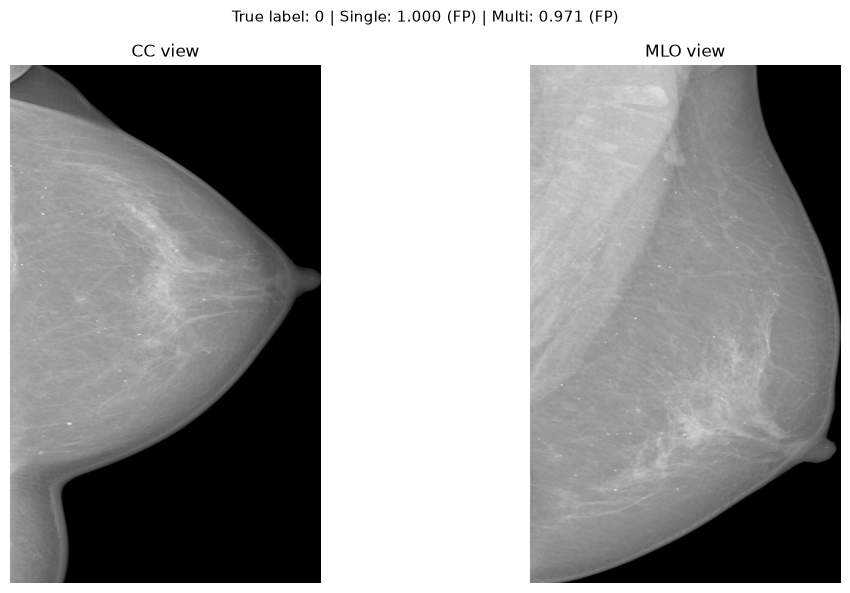

False positive — test row 1511


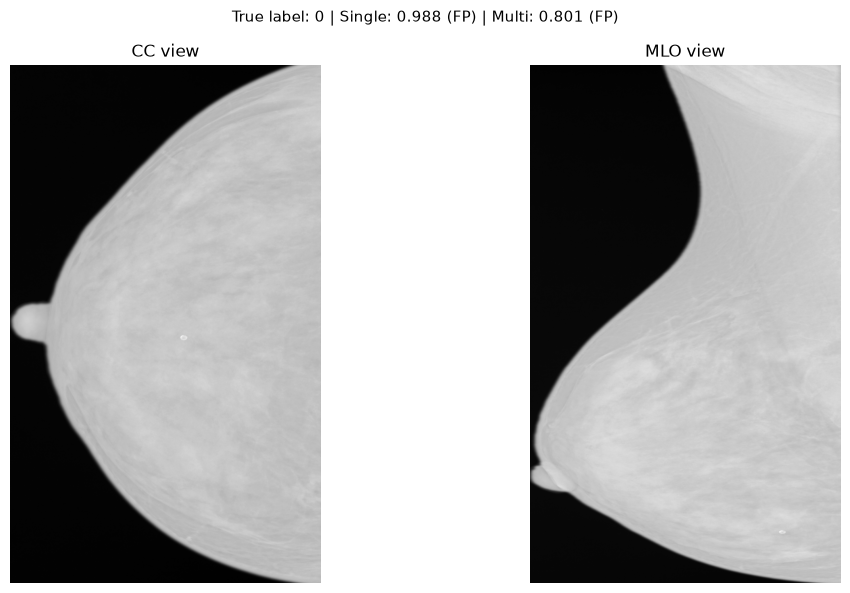

False positive — test row 1353


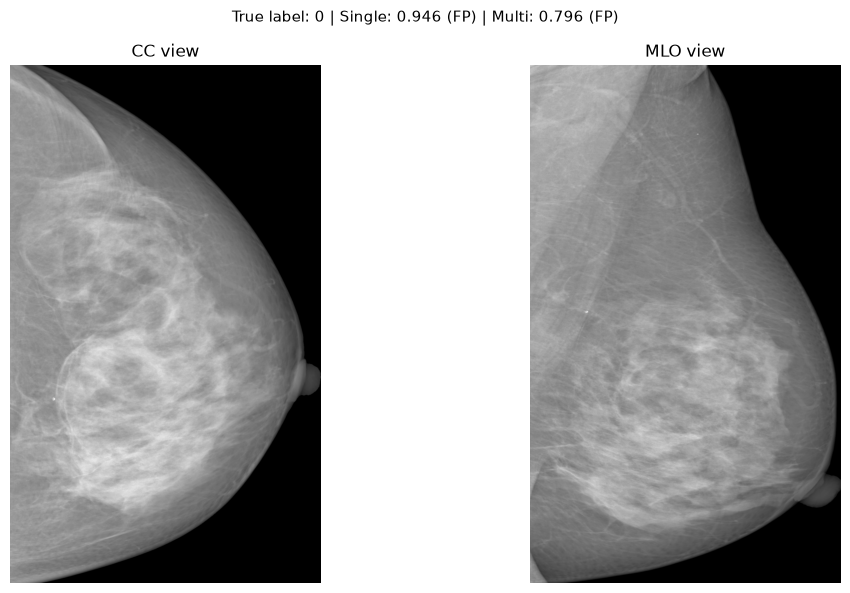

False positive — test row 1193


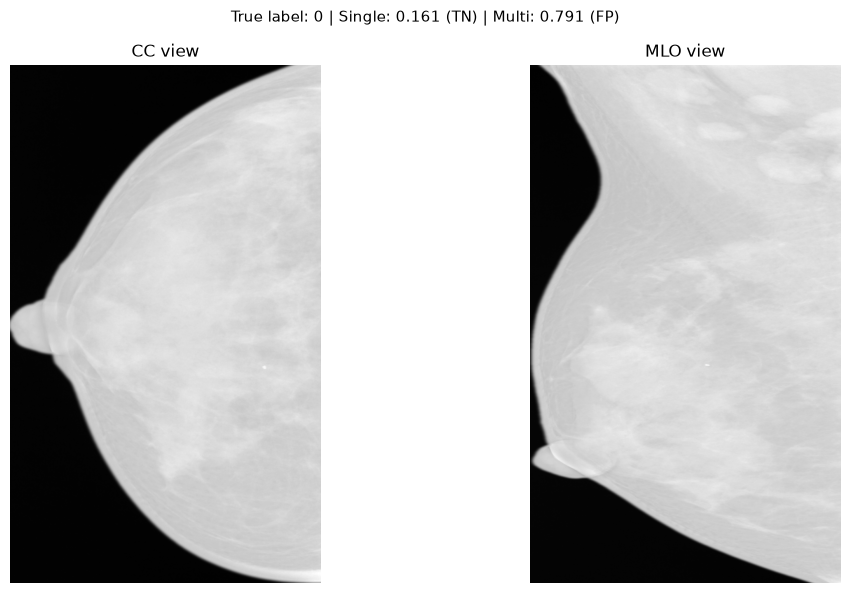

False positive — test row 198


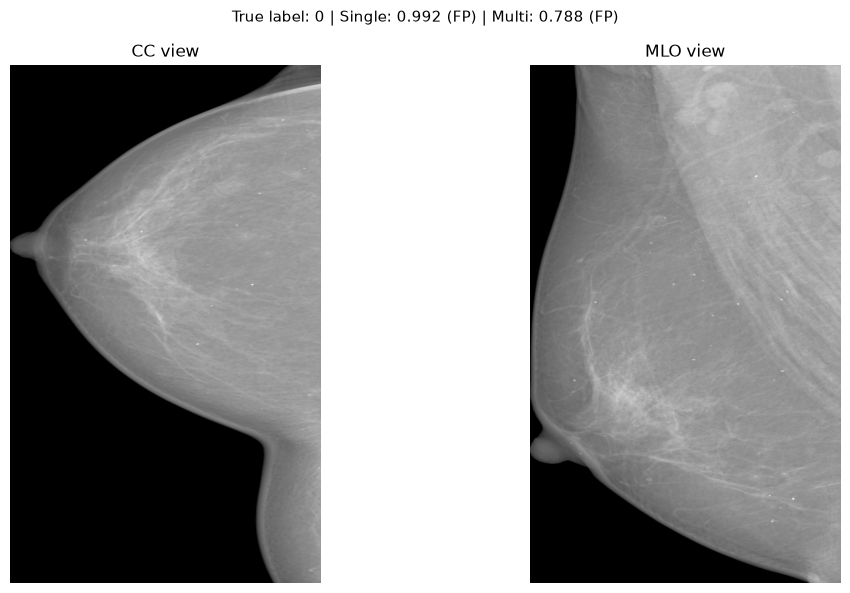

In [54]:
for index, row in fp_cases.iterrows():

    print(f"False positive — test row {index}")

    show_error_case(row)

### Visual Inspection of Misclassified Cases

The selected examples include false positives with positive-class scores ranging from approximately 0.788 to 0.971 and false negatives with scores ranging from approximately 0.130 to 0.243.

Several mistakes were associated with highly confident predictions, indicating that the model can assign strong scores to an incorrect BI-RADS-derived class.

Both CC and MLO images were displayed for each case. However, the underlying causes of these errors cannot be established from classification scores alone. Further examination of image characteristics and Grad-CAM activation maps is necessary.

False negative — test row 1072


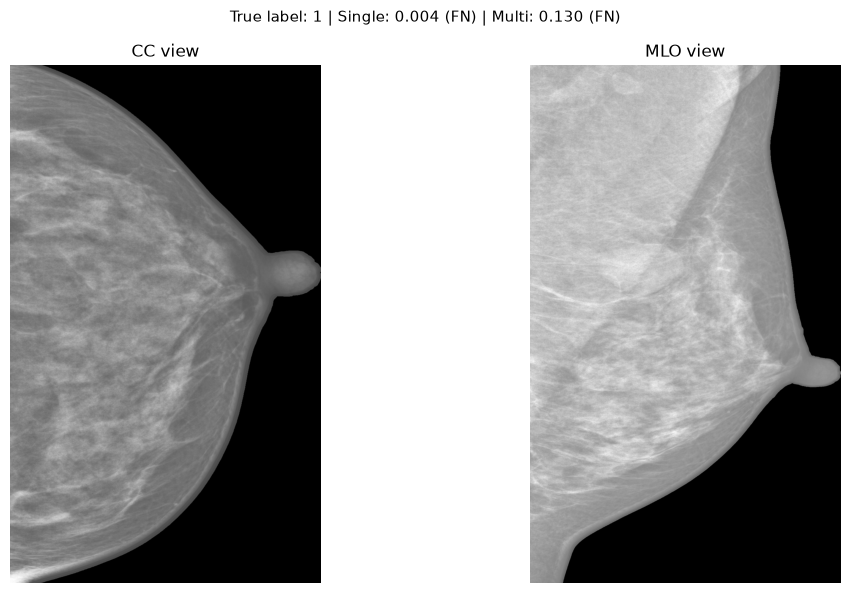

False negative — test row 1728


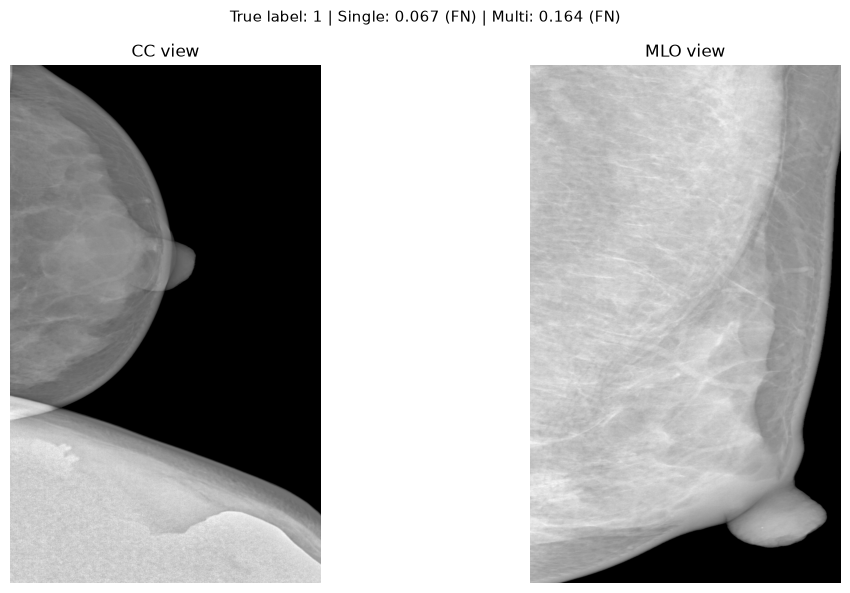

False negative — test row 292


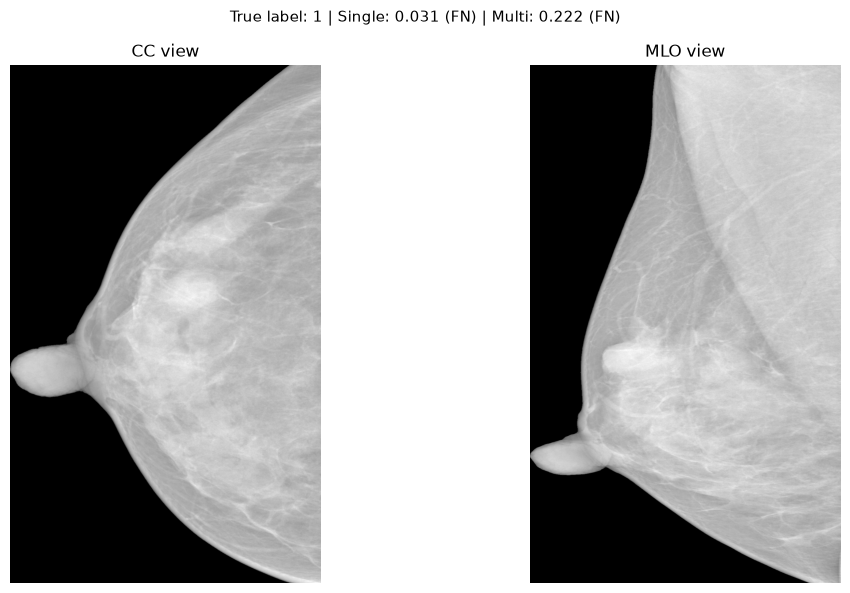

False negative — test row 693


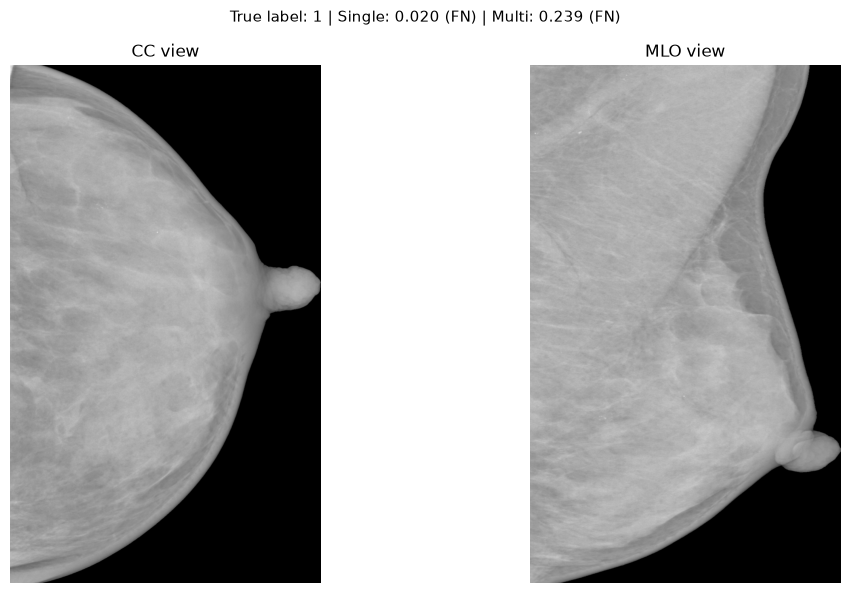

False negative — test row 175


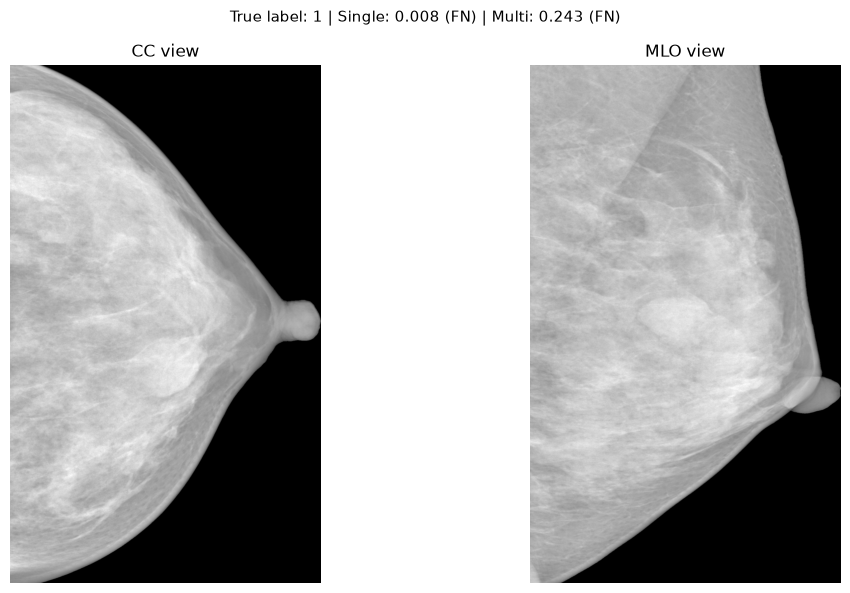

In [55]:
for index, row in fn_cases.iterrows():

    print(f"False negative — test row {index}")

    show_error_case(row)

High-confidence error — test row 197 | Wrong-class score: 0.9710


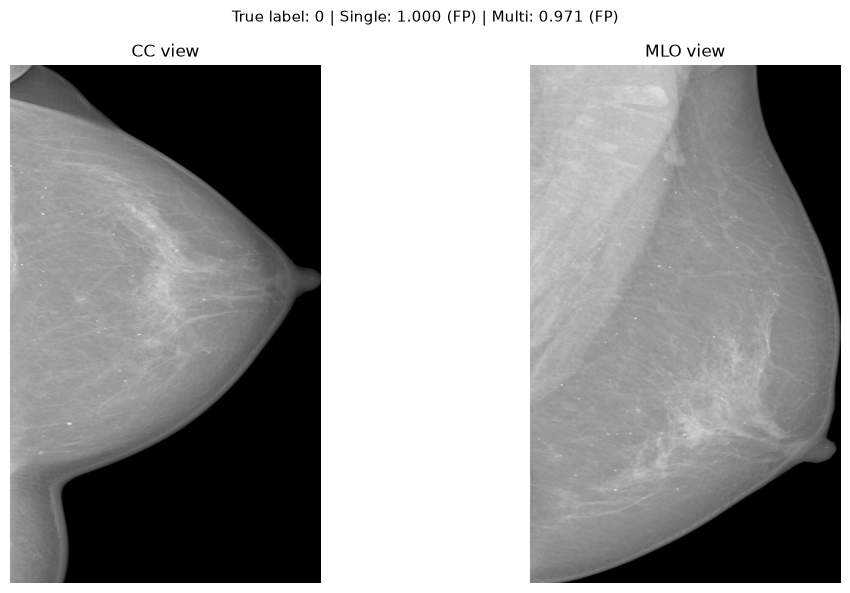

High-confidence error — test row 1072 | Wrong-class score: 0.8702


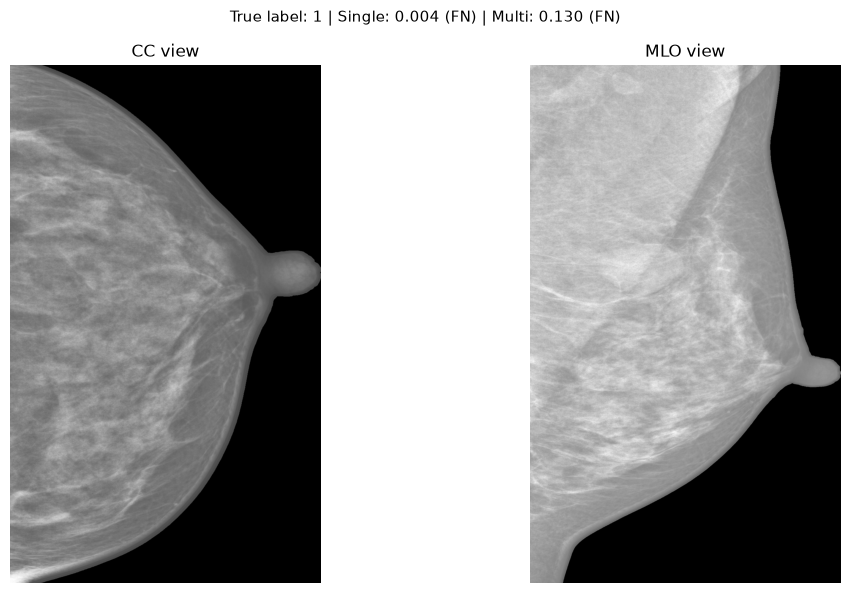

High-confidence error — test row 1728 | Wrong-class score: 0.8359


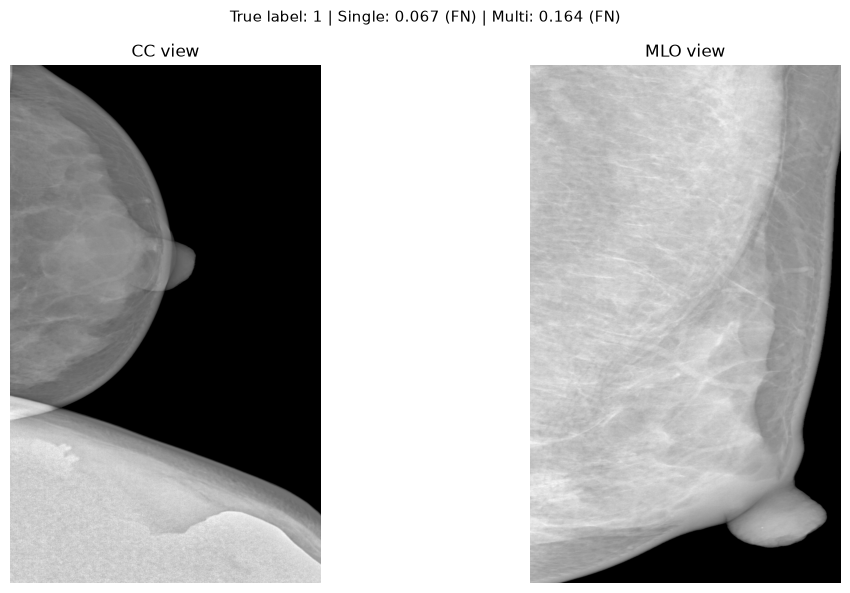

High-confidence error — test row 1511 | Wrong-class score: 0.8013


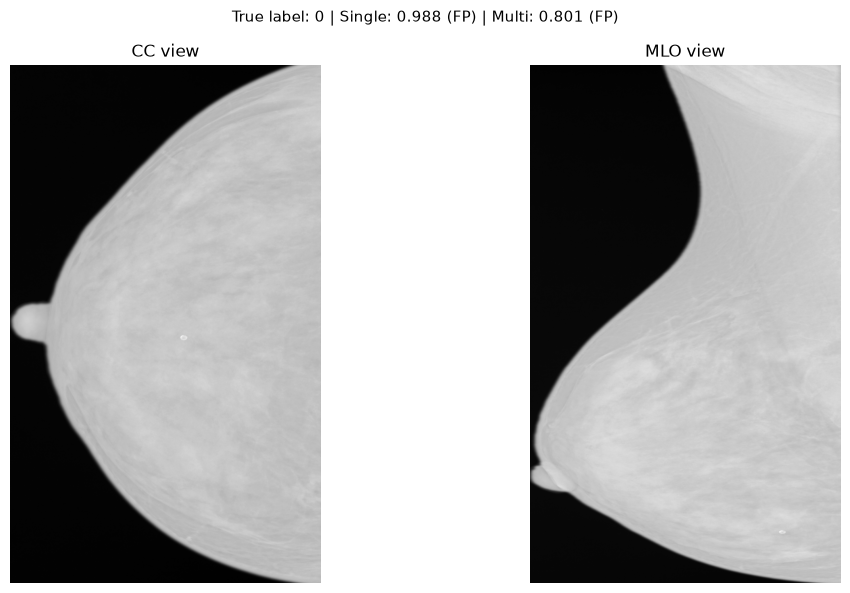

High-confidence error — test row 1353 | Wrong-class score: 0.7958


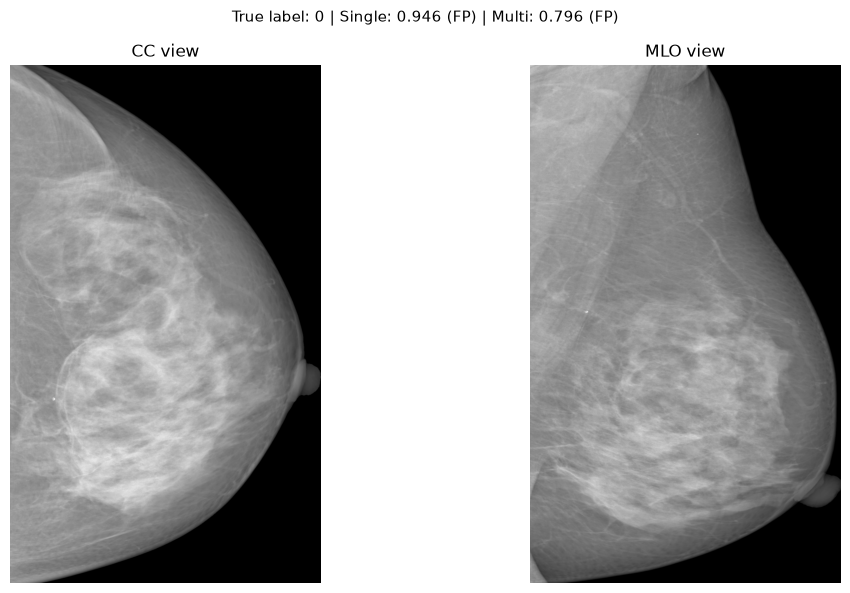

In [56]:
for index, row in high_confidence_cases.iterrows():

    print(
        f"High-confidence error — test row {index} | "
        f"Wrong-class score: "
        f"{row['Wrong-class confidence']:.4f}"
    )

    show_error_case(row)

In [57]:
corrected_cases = error_analysis_df[
    (error_analysis_df["Single outcome"].isin(["FP", "FN"]))
    & (error_analysis_df["Multi outcome"].isin(["TP", "TN"]))
].copy()

introduced_errors = error_analysis_df[
    (error_analysis_df["Single outcome"].isin(["TP", "TN"]))
    & (error_analysis_df["Multi outcome"].isin(["FP", "FN"]))
].copy()

both_wrong = error_analysis_df[
    (error_analysis_df["Single outcome"].isin(["FP", "FN"]))
    & (error_analysis_df["Multi outcome"].isin(["FP", "FN"]))
].copy()

comparison_counts = pd.DataFrame({
    "Category": [
        "Errors corrected by multi-view",
        "New errors introduced by multi-view",
        "Both models incorrect"
    ],
    "Count": [
        len(corrected_cases),
        len(introduced_errors),
        len(both_wrong)
    ]
})

display(comparison_counts)

,Category,Count
0,Errors corrected by multi-view,91
1,New errors introduced by multi-view,134
2,Both models incorrect,130


### Comparison of Single-view and Multi-view Errors

At seed 42, multi-view classification corrected 91 errors made by the single-view model, but introduced 134 new errors on cases that the single-view model classified correctly. Both architectures misclassified the same 130 breast-level cases.

The multi-view model therefore made 43 more classification errors at the fixed threshold of 0.5.

These results demonstrate that adding the MLO view does not necessarily improve individual binary decisions, even when discrimination metrics such as AUPRC are higher. The observed differences may reflect changes in score distributions, decision thresholds, or the learned image representations.


Corrected by multi-view: 91 cases
Test row: 54


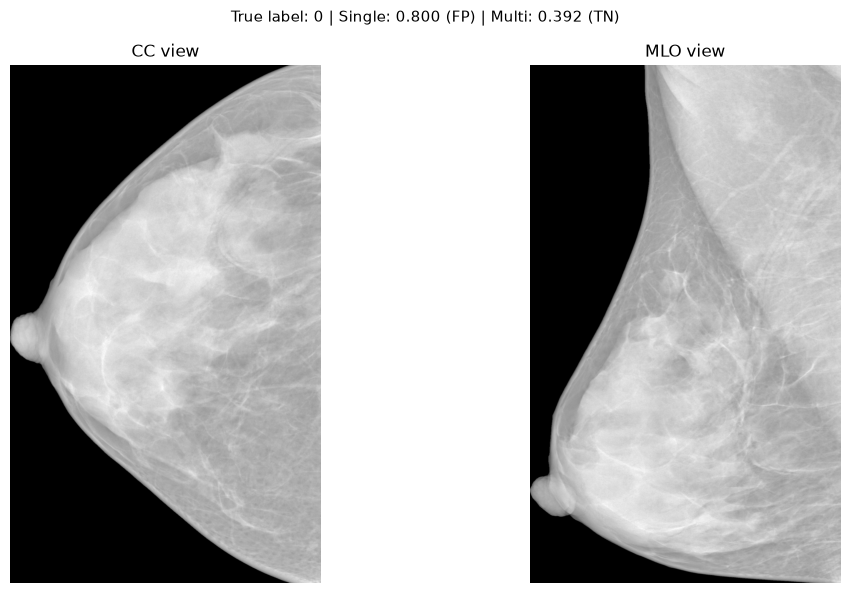

Test row: 66


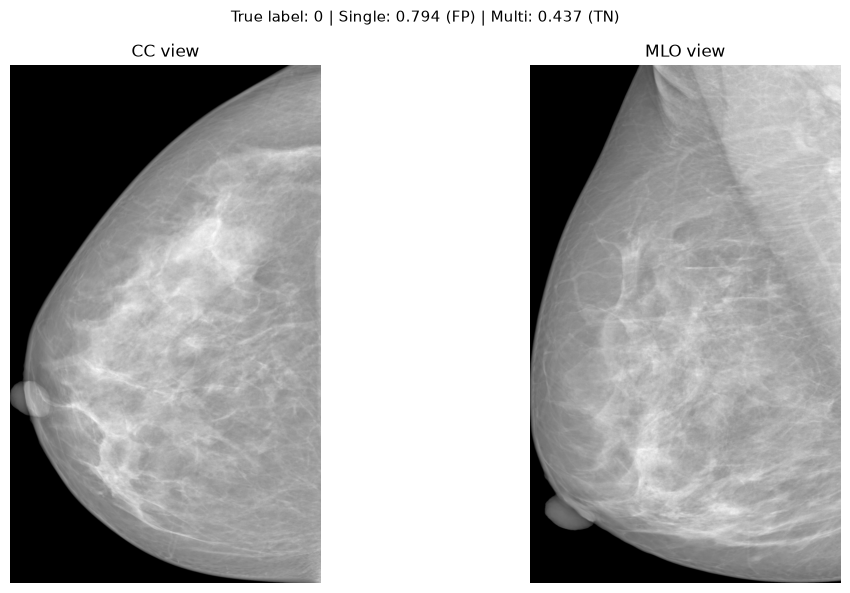

Test row: 71


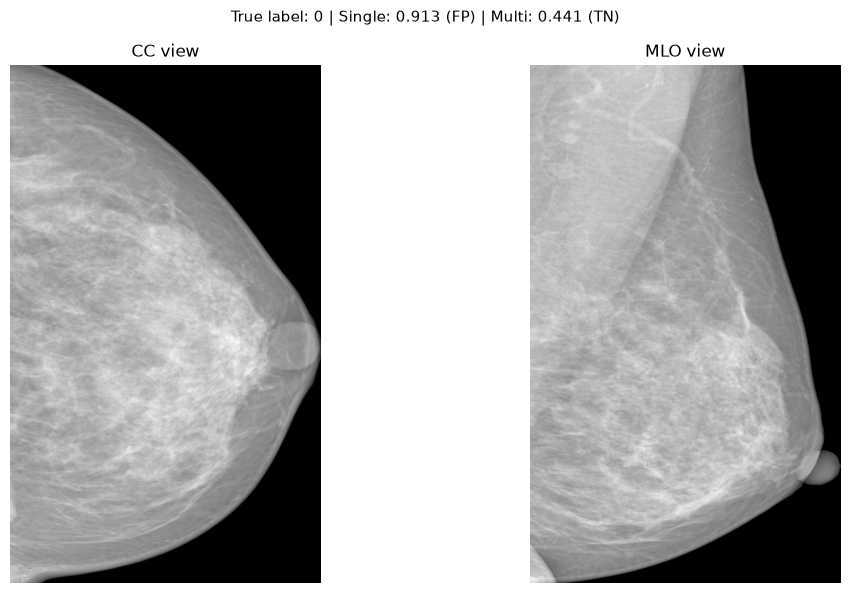


Introduced by multi-view: 134 cases
Test row: 3


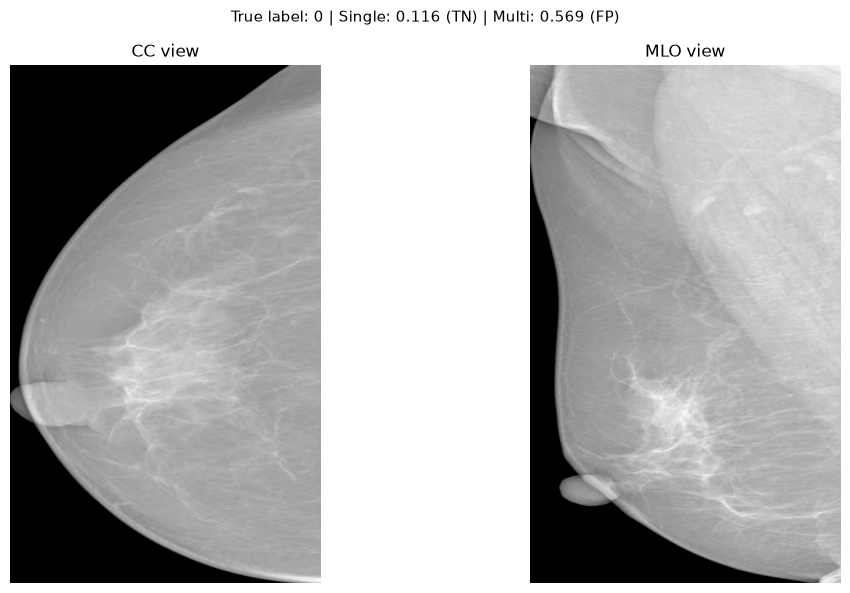

Test row: 59


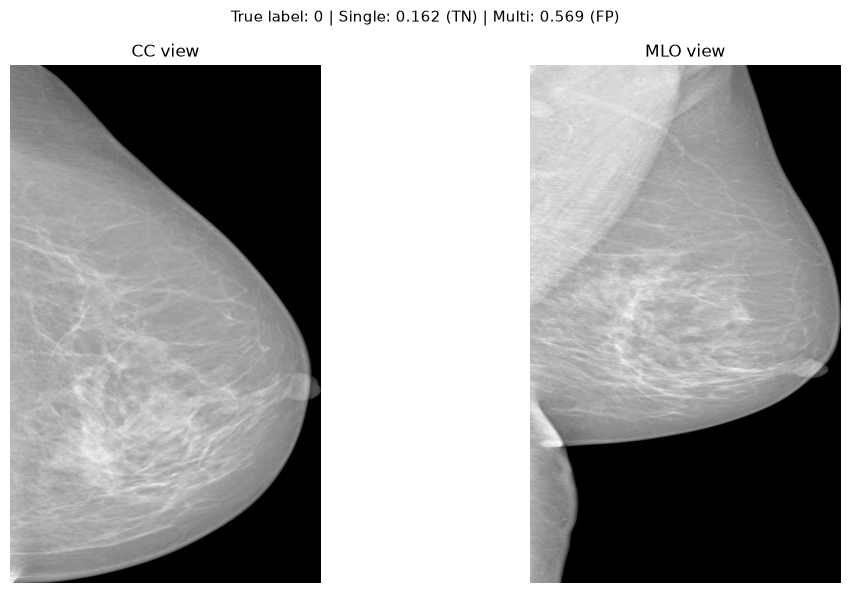

Test row: 60


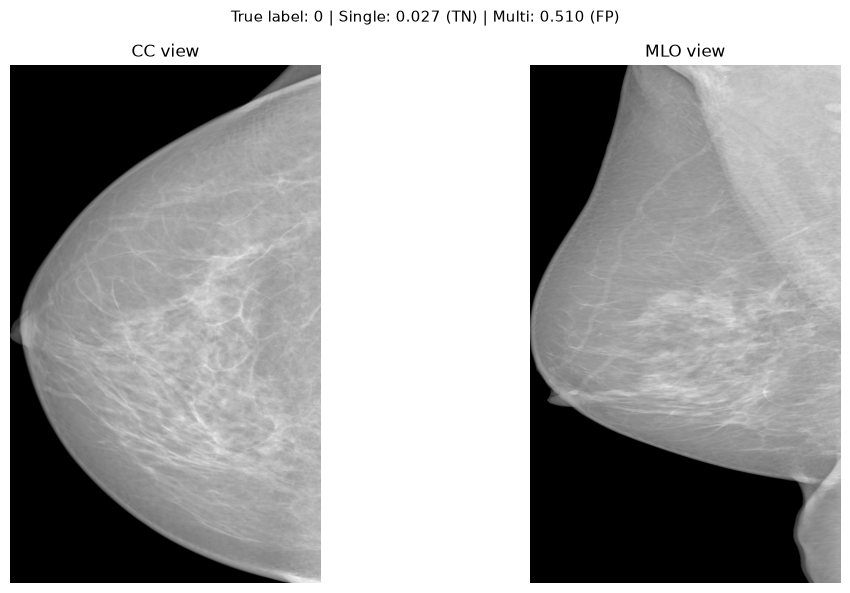

In [58]:
for name, cases in [
    ("Corrected by multi-view", corrected_cases),
    ("Introduced by multi-view", introduced_errors)
]:

    print(f"\n{name}: {len(cases)} cases")

    for index, row in cases.head(3).iterrows():
        print(f"Test row: {index}")
        show_error_case(row)

### Case-level Prediction Differences

Examples of corrected and newly introduced errors were visualized using paired CC and MLO mammograms.

The results demonstrate that multi-view fusion changes individual predictions in both beneficial and detrimental ways. Nevertheless, disagreement between the models does not establish which image regions or anatomical features caused the differences.

The selected cases will be examined further using Grad-CAM to investigate the spatial distribution of model attention.

In [59]:
selected_cases = pd.concat(
    [
        fp_cases.assign(Selection="False positive"),
        fn_cases.assign(Selection="False negative"),
        high_confidence_cases.assign(
            Selection="High-confidence mistake"
        )
    ]
)

selected_cases.index.name = "Test row"
selected_cases = selected_cases.reset_index()

selected_cases["Visual observation"] = ""
selected_cases["Possible explanation"] = ""
selected_cases["Image quality"] = ""
selected_cases["Grad-CAM observation"] = ""

review_path = RESULTS_DIR / "qualitative_error_review.csv"

if not review_path.exists():
    selected_cases.to_csv(
        review_path,
        index=False
    )
    print("Review table created:", review_path)
else:
    print("Existing review table preserved:", review_path)

display(
    selected_cases[
        [
            "Test row",
            "Selection",
            "target",
            "Single probability",
            "Multi probability",
            "Visual observation",
            "Possible explanation"
        ]
    ]
)

Review table created: c:\Users\Admin\Desktop\Projects\5_sem\DeepLearning\lab4\results\evaluation\qualitative_error_review.csv


,Test row,Selection,target,Single probability,Multi probability,Visual observation,Possible explanation
0,197,False positive,0,0.999988,0.970964,,
1,1511,False positive,0,0.987616,0.801315,,
2,1353,False positive,0,0.945901,0.795817,,
3,1193,False positive,0,0.161320,0.790692,,
4,198,False positive,0,0.991684,0.787768,,
5,1072,False negative,1,0.004281,0.129843,,
6,1728,False negative,1,0.067424,0.164114,,
7,292,False negative,1,0.031262,0.221687,,
8,693,False negative,1,0.019644,0.239172,,
9,175,False negative,1,0.008156,0.242923,,


### Error Analysis Summary

The error analysis identified representative false positives, false negatives, and high-confidence mistakes in the held-out test set.

At the predefined decision threshold, multi-view classification corrected 91 single-view errors but introduced 134 new mistakes. Both models failed on 130 identical breast-level cases.

These findings highlight the importance of evaluating individual predictions in addition to aggregate discrimination metrics. The selected mammograms provide a basis for subsequent Grad-CAM analysis and qualitative investigation of possible model failure mechanisms.

## 5.7	Grad-CAM Explainability

In [60]:
gradcam_model = load_final_checkpoint(
    model_name="multi_view",
    seed=42
)

gradcam_model.eval()

print("Grad-CAM model loaded.")
print("CC target:", gradcam_model.cc_encoder.layer4[-1].conv3)
print("MLO target:", gradcam_model.mlo_encoder.layer4[-1].conv3)

Grad-CAM model loaded.
CC target: Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
MLO target: Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [61]:
class MultiViewGradCAM:

    def __init__(self, model):
        self.model = model
        self.activations = {}
        self.gradients = {}
        self.handles = []

        layers = {
            "CC": model.cc_encoder.layer4[-1].conv3,
            "MLO": model.mlo_encoder.layer4[-1].conv3
        }

        for view, layer in layers.items():

            self.handles.append(
                layer.register_forward_hook(
                    self._activation_hook(view)
                )
            )

    def _activation_hook(self, view):

        def hook(module, inputs, output):

            self.activations[view] = output.detach()

            if output.requires_grad:
                output.register_hook(
                    lambda grad, v=view: self.gradients.__setitem__(
                        v, grad.detach()
                    )
                )

        return hook

    def generate(self, cc, mlo):

        self.activations.clear()
        self.gradients.clear()

        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        logits = self.model(cc, mlo)

        # Explain positive-class evidence.
        score = logits[0, 0]
        score.backward()

        maps = {}

        for view in ["CC", "MLO"]:

            activations = self.activations[view]
            gradients = self.gradients[view]

            weights = gradients.mean(
                dim=(2, 3),
                keepdim=True
            )

            cam = torch.relu(
                (weights * activations).sum(
                    dim=1,
                    keepdim=True
                )
            )

            cam = torch.nn.functional.interpolate(
                cam,
                size=(FINAL_SIZE, FINAL_SIZE),
                mode="bilinear",
                align_corners=False
            )

            cam = cam[0, 0].cpu().numpy()

            cam = cam - cam.min()

            if cam.max() > 0:
                cam = cam / cam.max()

            maps[view] = cam

        probability = torch.sigmoid(
            logits.detach()
        ).item()

        return maps, probability

    def remove_hooks(self):
        for handle in self.handles:
            handle.remove()

        self.handles.clear()

In [62]:
def prepare_gradcam_images(row):

    image_tensors = {}
    display_images = {}

    for view in ["CC", "MLO"]:

        with Image.open(row[f"{view}_path"]) as image:
            image = image.convert("RGB")

            # Exactly the same model preprocessing
            image_tensors[view] = (
                final_transform(image)
                .unsqueeze(0)
                .to(device)
            )

            # Same geometry, without normalization
            display_image = ResizeWithPadding(FINAL_SIZE)(
                image.convert("L")
            )

            display_images[view] = np.asarray(
                display_image
            )

    return image_tensors, display_images

In [63]:
def show_gradcam_case(row, gradcam, save_path=None):

    image_tensors, display_images = prepare_gradcam_images(row)

    maps, probability = gradcam.generate(
        image_tensors["CC"],
        image_tensors["MLO"]
    )

    fig, axes = plt.subplots(
        2, 2,
        figsize=(11, 11)
    )

    for col, view in enumerate(["CC", "MLO"]):

        image = display_images[view]
        cam = maps[view]

        axes[0, col].imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=255
        )
        axes[0, col].set_title(f"{view} Original")

        axes[1, col].imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[1, col].imshow(
            cam,
            cmap="jet",
            alpha=0.40,
            vmin=0,
            vmax=1
        )

        axes[1, col].set_title(f"{view} Grad-CAM")

    for ax in axes.flat:
        ax.axis("off")

    fig.suptitle(
        f"True label: {int(row['target'])} | "
        f"Multi-view score: {probability:.3f} | "
        f"Outcome: {row['Multi outcome']}",
        fontsize=12
    )

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight"
        )

    plt.show()
    plt.close(fig)

    return maps, probability

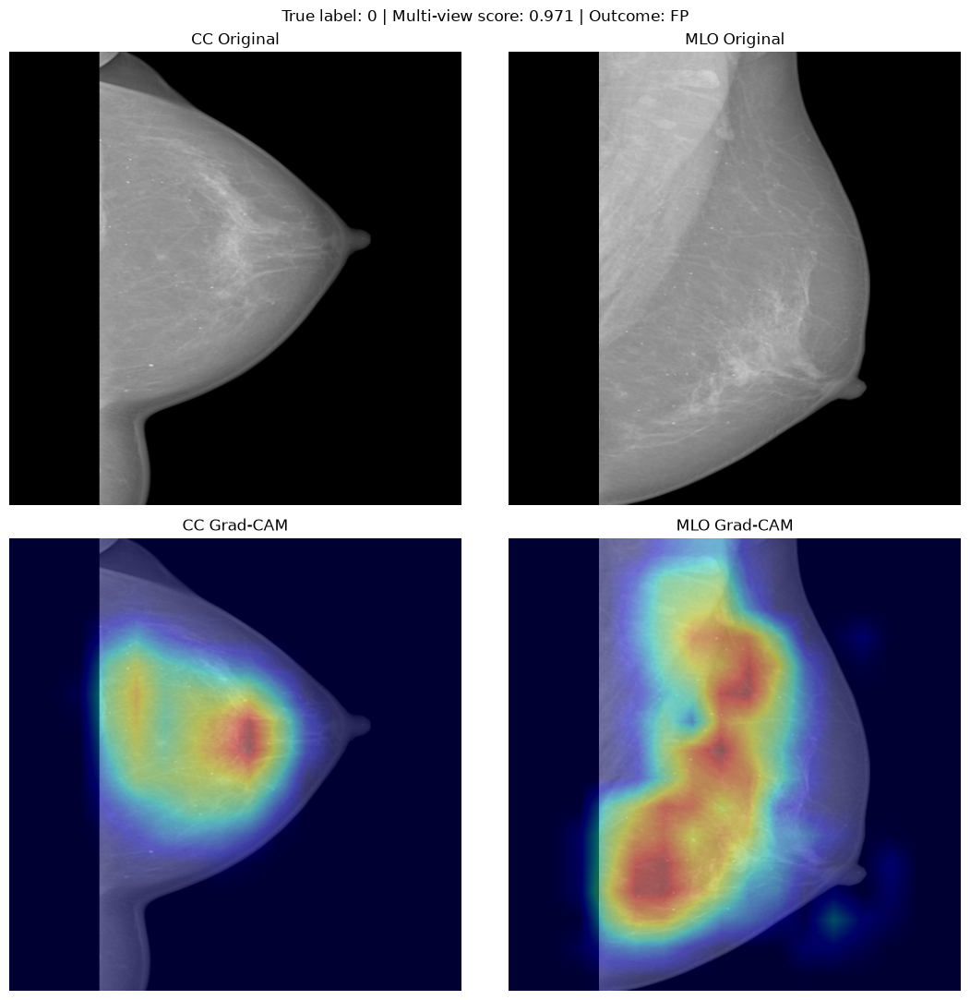

Predicted score: 0.971
CC map shape: (512, 512)
MLO map shape: (512, 512)


In [64]:
gradcam = MultiViewGradCAM(gradcam_model)

example = fp_cases.iloc[0]

maps, probability = show_gradcam_case(
    example,
    gradcam
)

print("Predicted score:", round(probability, 4))
print("CC map shape:", maps["CC"].shape)
print("MLO map shape:", maps["MLO"].shape)

In [66]:
assert np.isclose(
    probability,
    float(example["Multi probability"]),
    atol=1e-4
)

print("Grad-CAM prediction matches saved test prediction.")

Grad-CAM prediction matches saved test prediction.


### Grad-CAM Verification

Grad-CAM was successfully generated for both CC and MLO views at a resolution of 512 × 512 pixels.

The model's predicted score matched the previously saved test prediction, confirming consistency between the explainability pipeline and the original evaluation.

The heatmaps represent spatial contributions to the positive-class logit and should not be interpreted as direct lesion segmentation or calibrated probabilities of malignancy.

In [67]:
gradcam_cases = {}

for outcome in ["TP", "TN", "FP", "FN"]:

    cases = error_analysis_df[
        error_analysis_df["Multi outcome"] == outcome
    ].copy()

    if outcome in ["TP", "FP"]:
        cases = cases.sort_values(
            "Multi probability",
            ascending=False
        )
    else:
        cases = cases.sort_values(
            "Multi probability",
            ascending=True
        )

    gradcam_cases[outcome] = cases.head(3)

    print(outcome, "selected:", len(gradcam_cases[outcome]))

TP selected: 3
TN selected: 3
FP selected: 3
FN selected: 3



TP cases
Test row: 1112


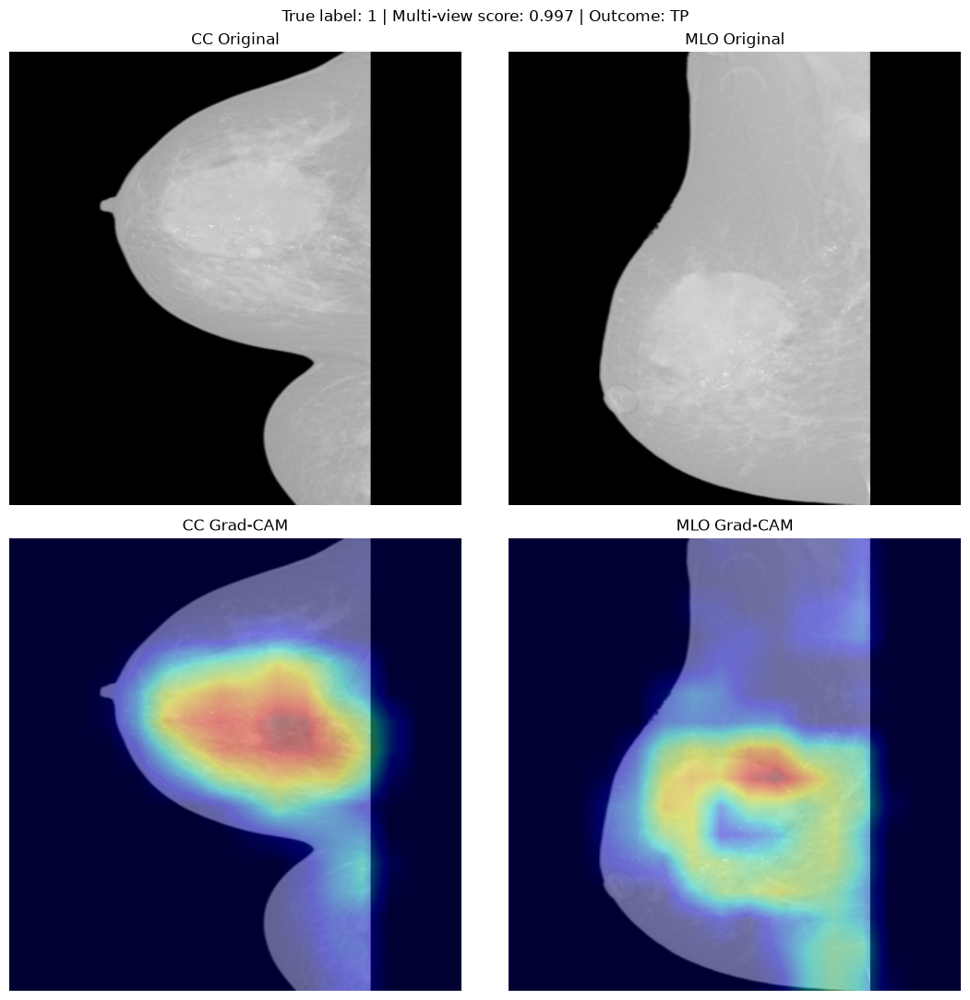

Test row: 1071


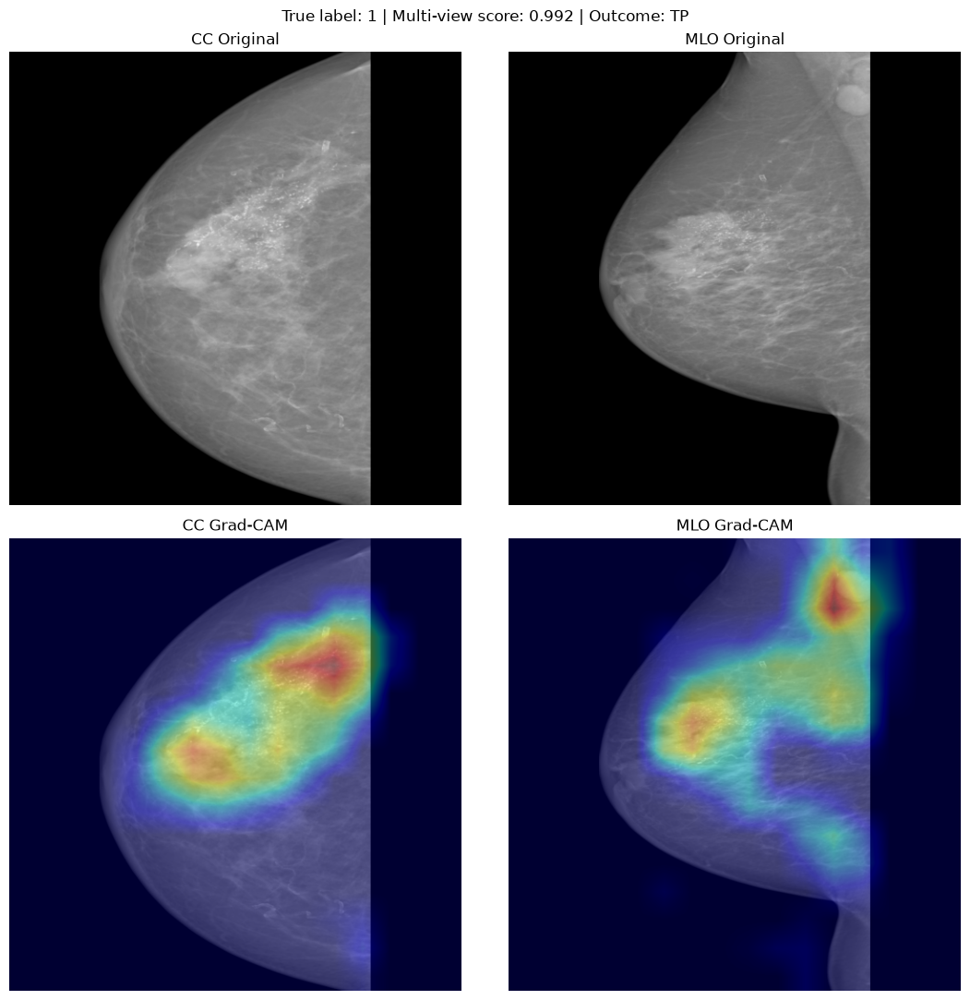

Test row: 369


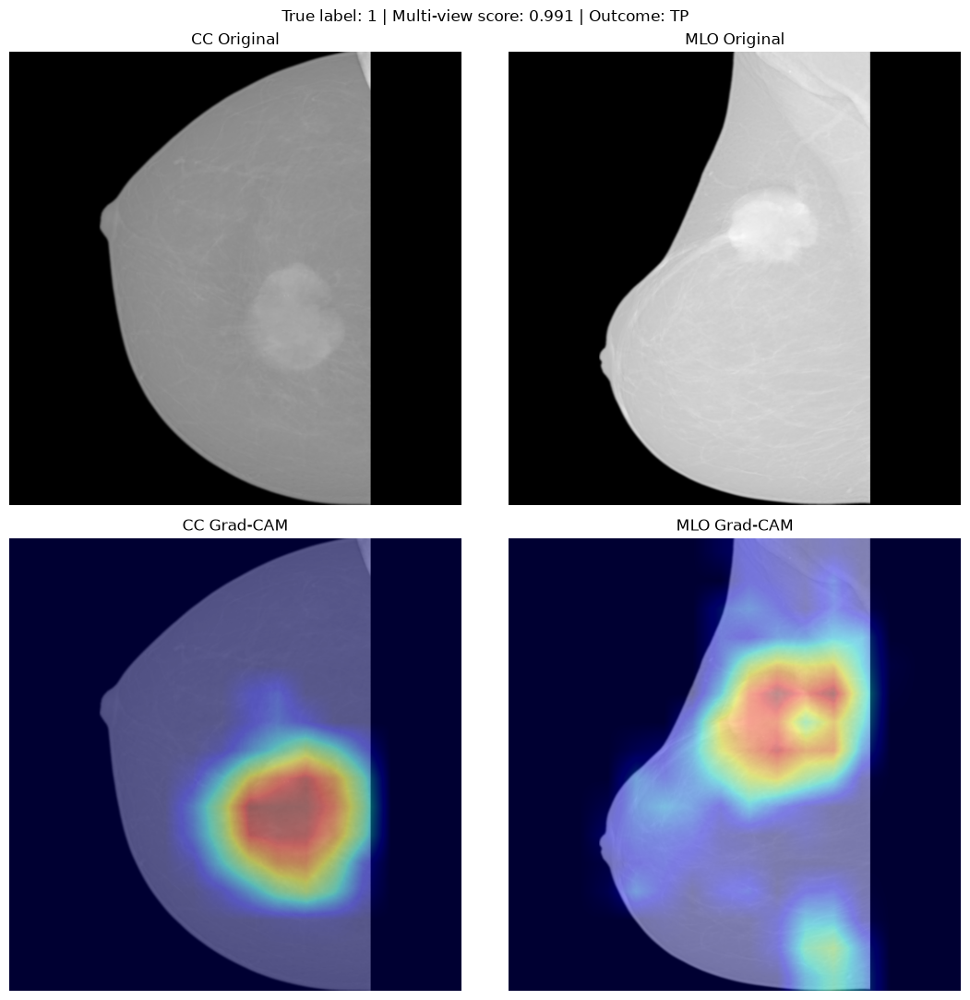


TN cases
Test row: 1624


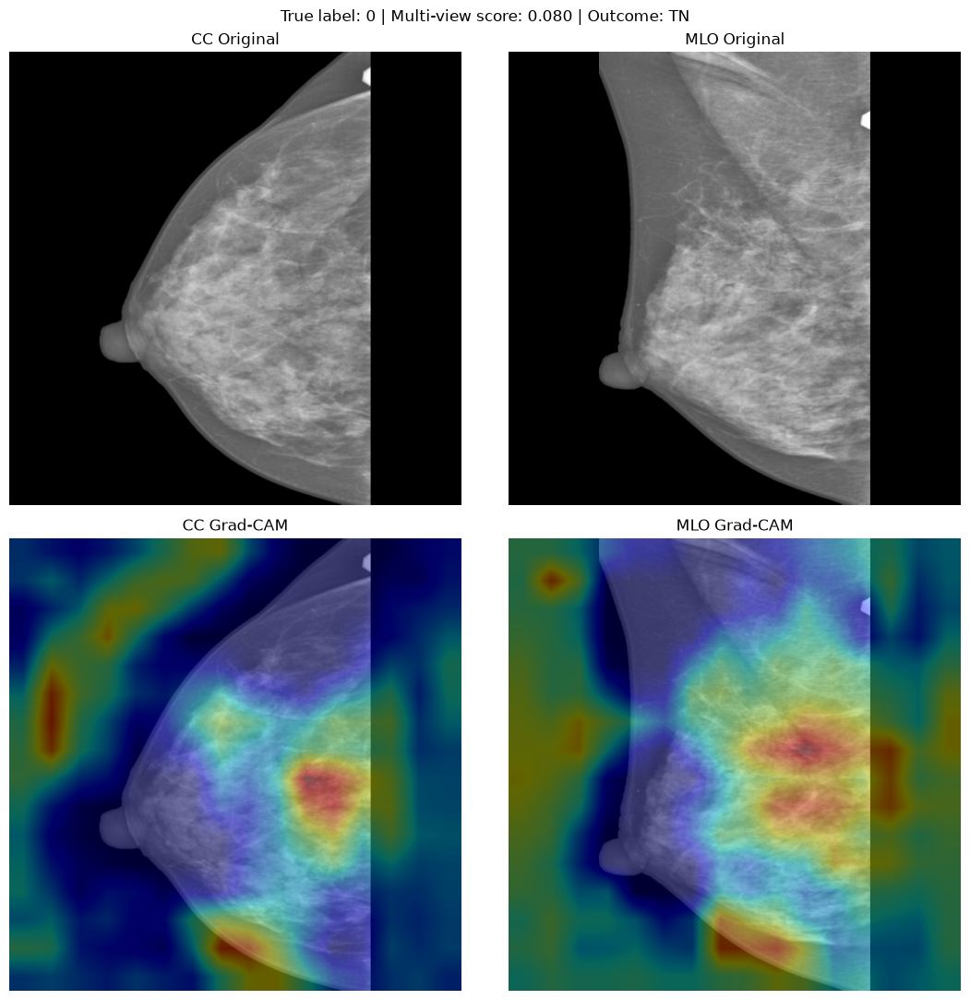

Test row: 1665


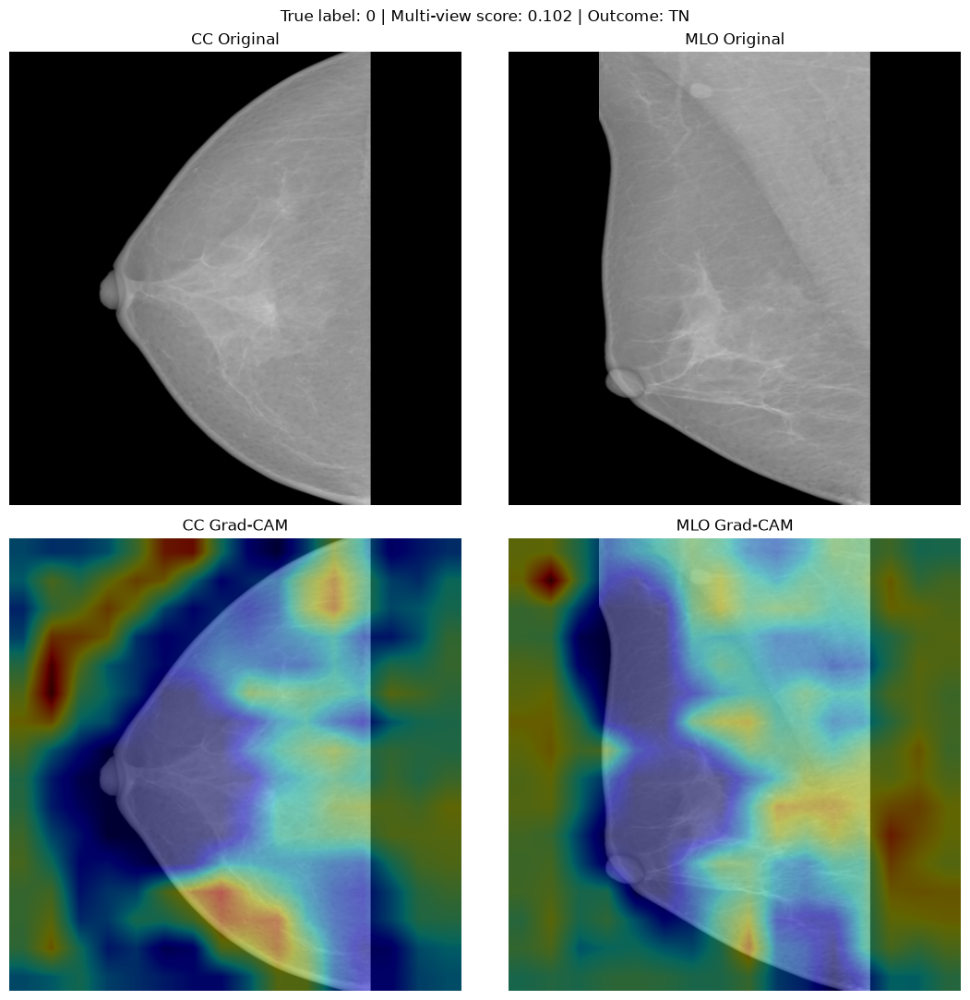

Test row: 698


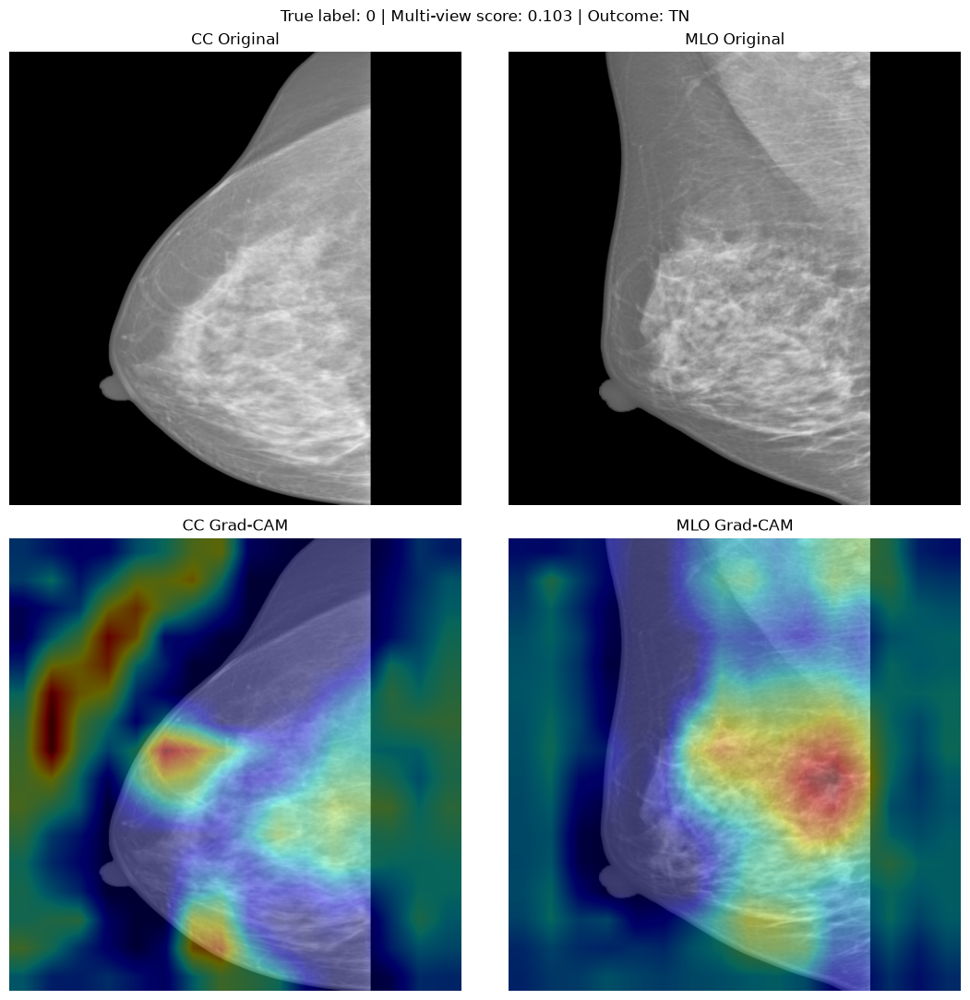


FP cases
Test row: 197


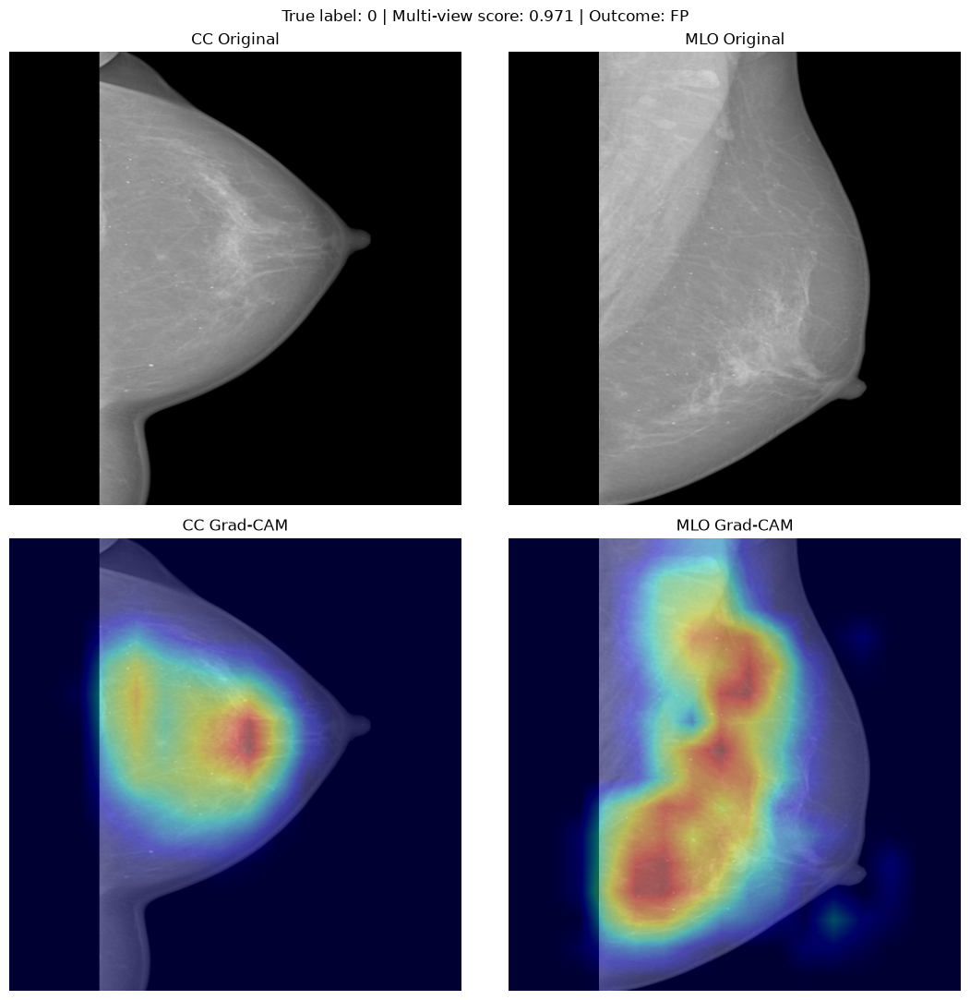

Test row: 1511


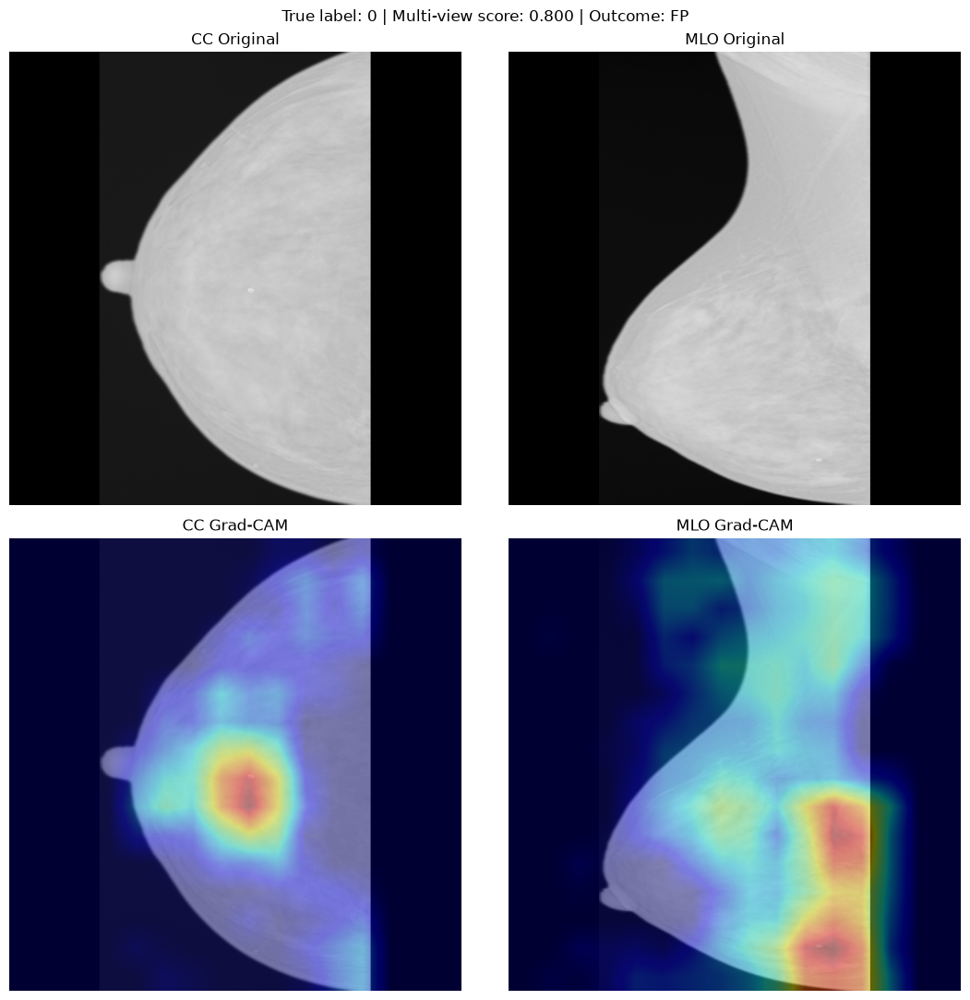

Test row: 1353


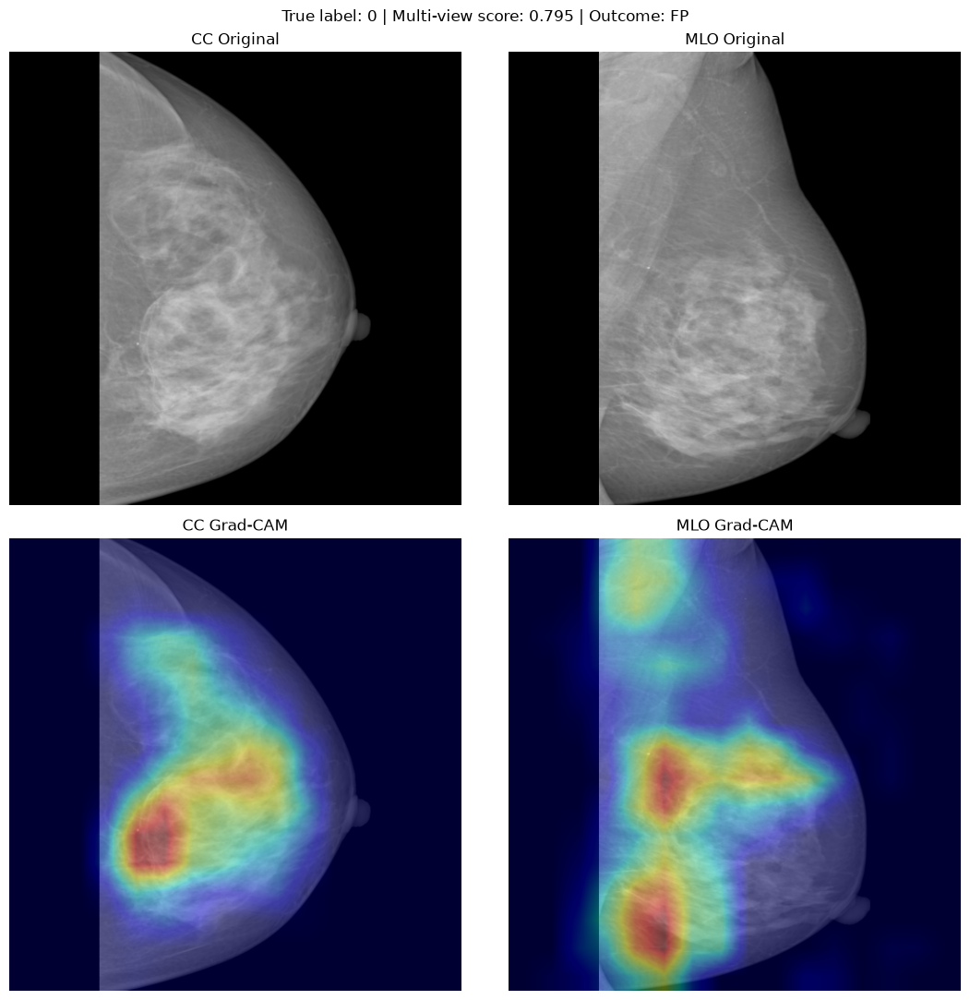


FN cases
Test row: 1072


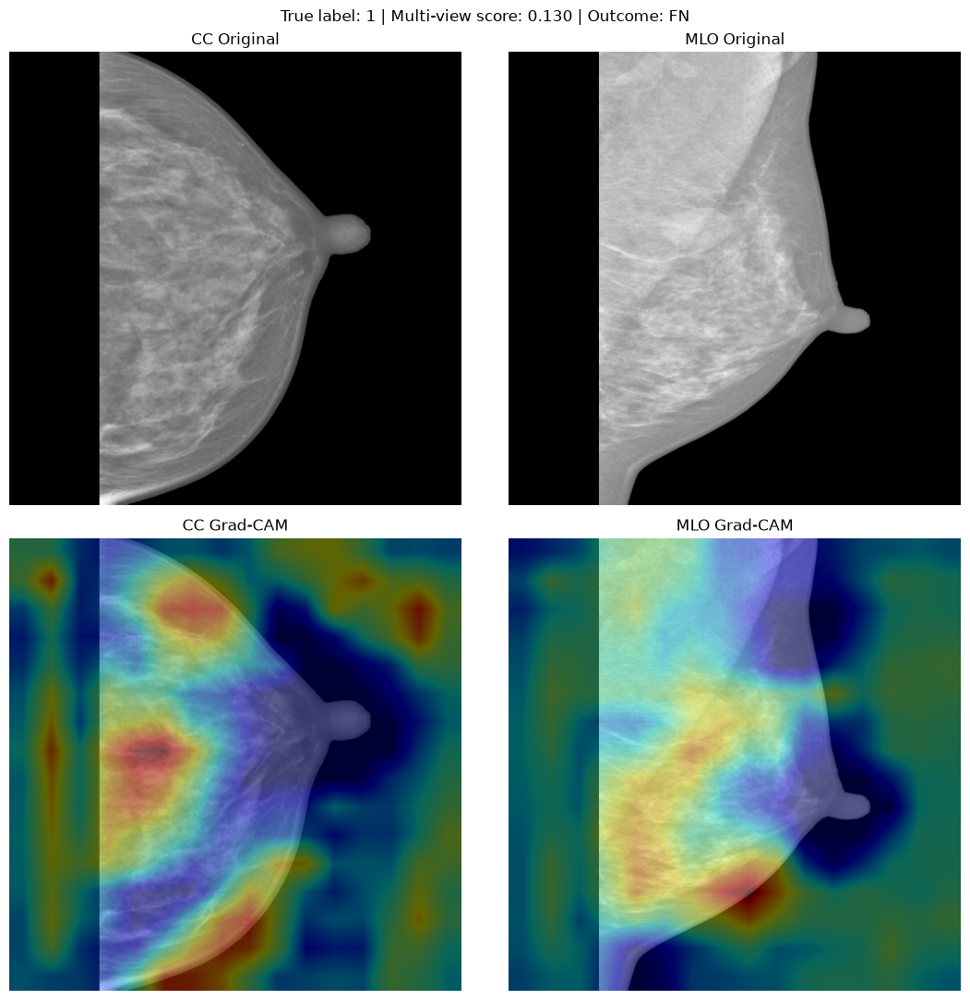

Test row: 1728


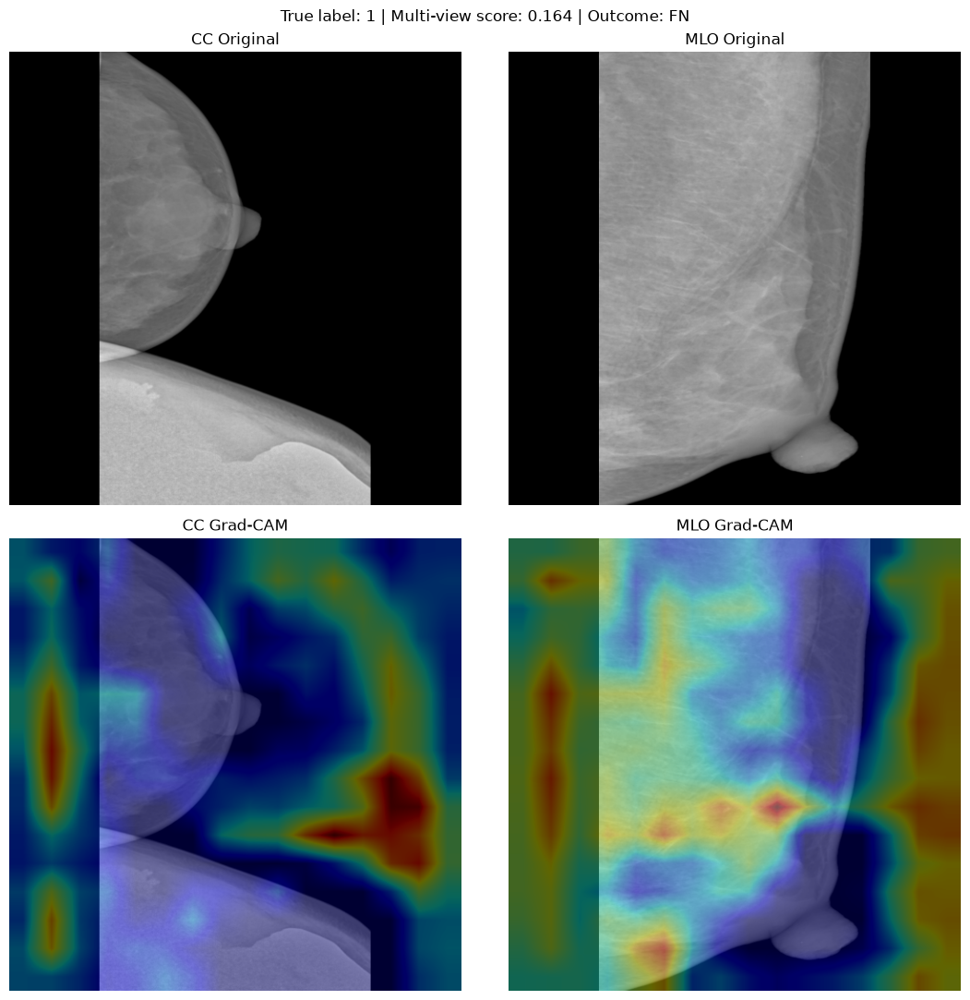

Test row: 292


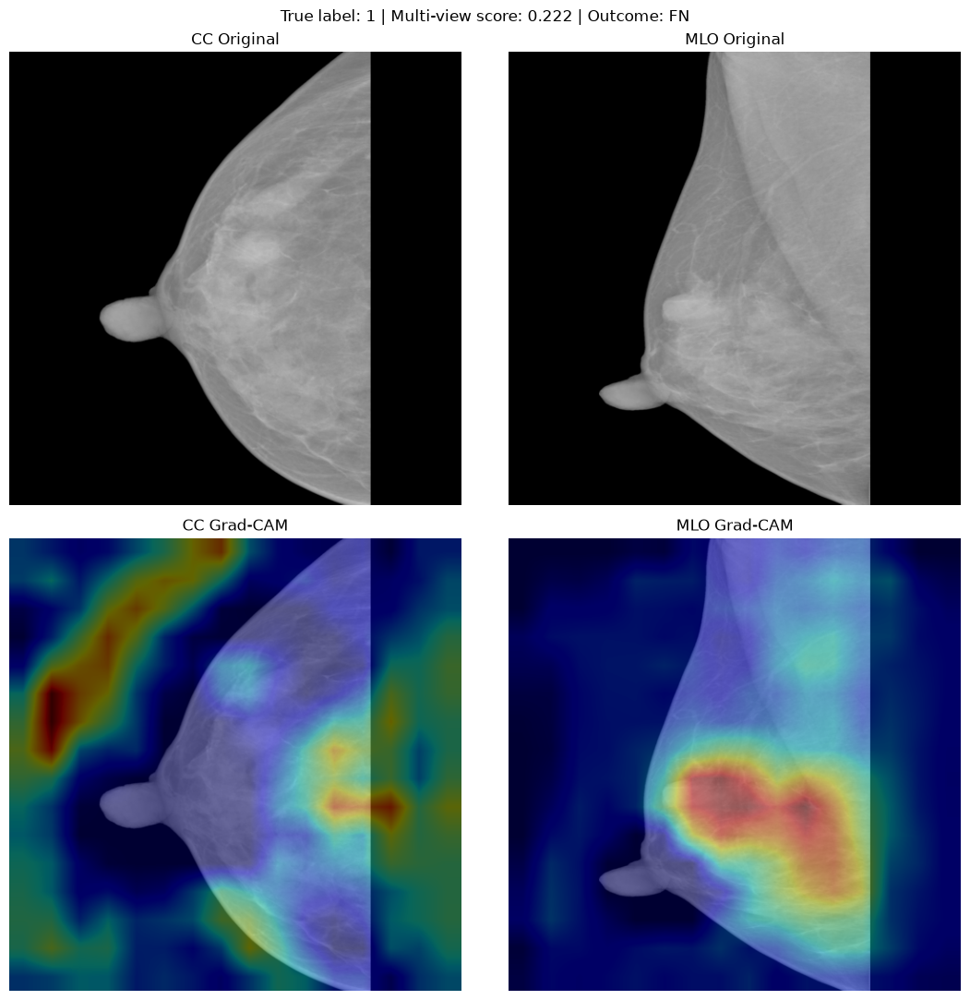

In [68]:
GRADCAM_DIR = RESULTS_DIR / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

for outcome, cases in gradcam_cases.items():

    print(f"\n{outcome} cases")

    for index, row in cases.iterrows():

        print(f"Test row: {index}")

        show_gradcam_case(
            row,
            gradcam,
            save_path=(
                GRADCAM_DIR
                / f"multiview_seed42_{outcome}_row{index}.png"
            )
        )

### Grad-CAM Results Across Prediction Outcomes

Grad-CAM visualizations were generated for three true positives, three true negatives, three false positives, and three false negatives.

In several true-positive cases, stronger activations were concentrated within breast tissue. However, some true-negative and misclassified cases also displayed activations along image boundaries or outside the breast region.

The activation patterns differed between CC and MLO views, suggesting that the two encoders respond to different spatial features.

These findings indicate that the model does not consistently focus on localized anatomical regions. Without lesion-level reference annotations, the clinical relevance of the highlighted areas cannot be confirmed.

corrected: test row 54


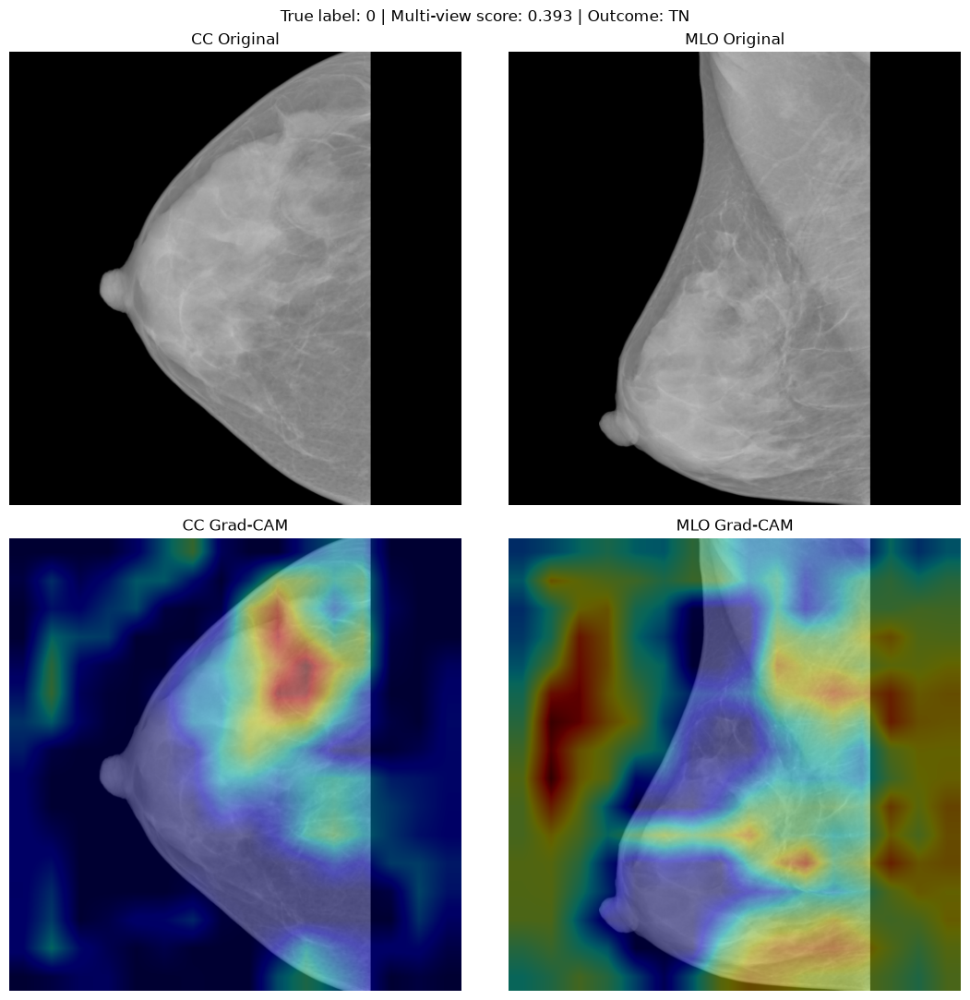

corrected: test row 66


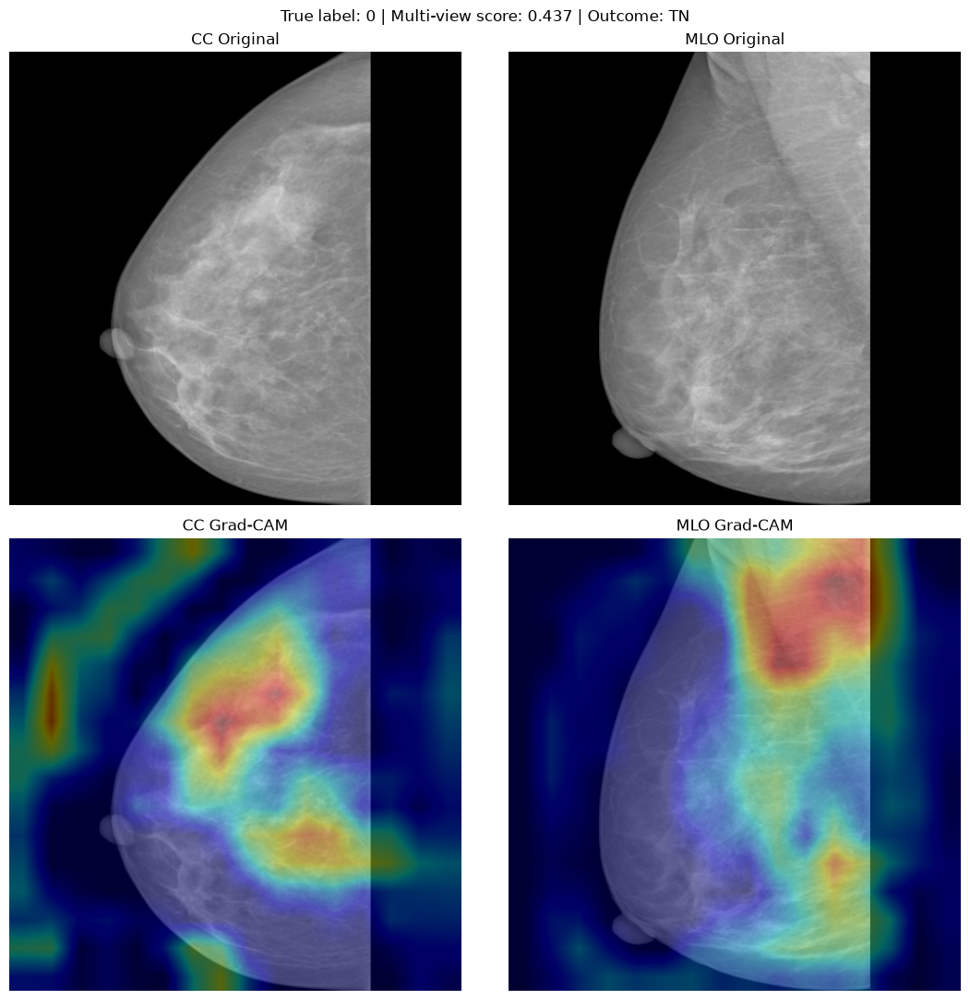

corrected: test row 71


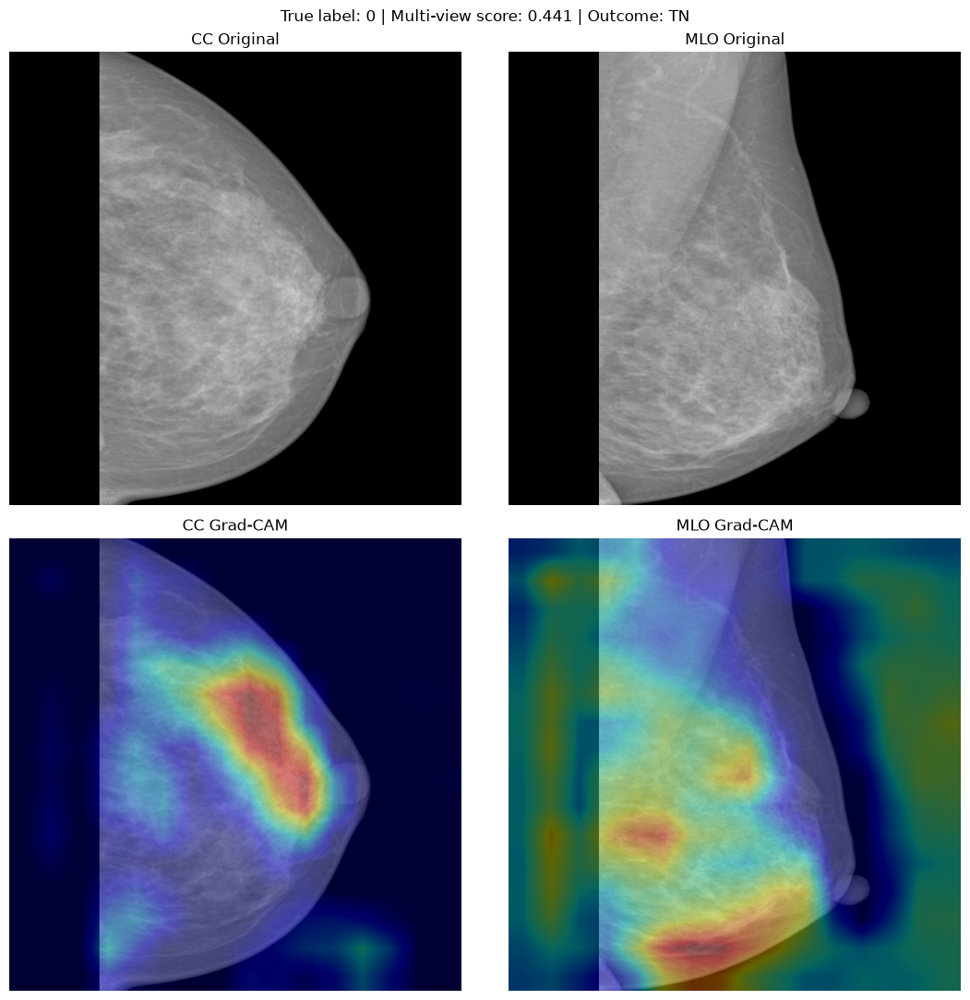

introduced: test row 3


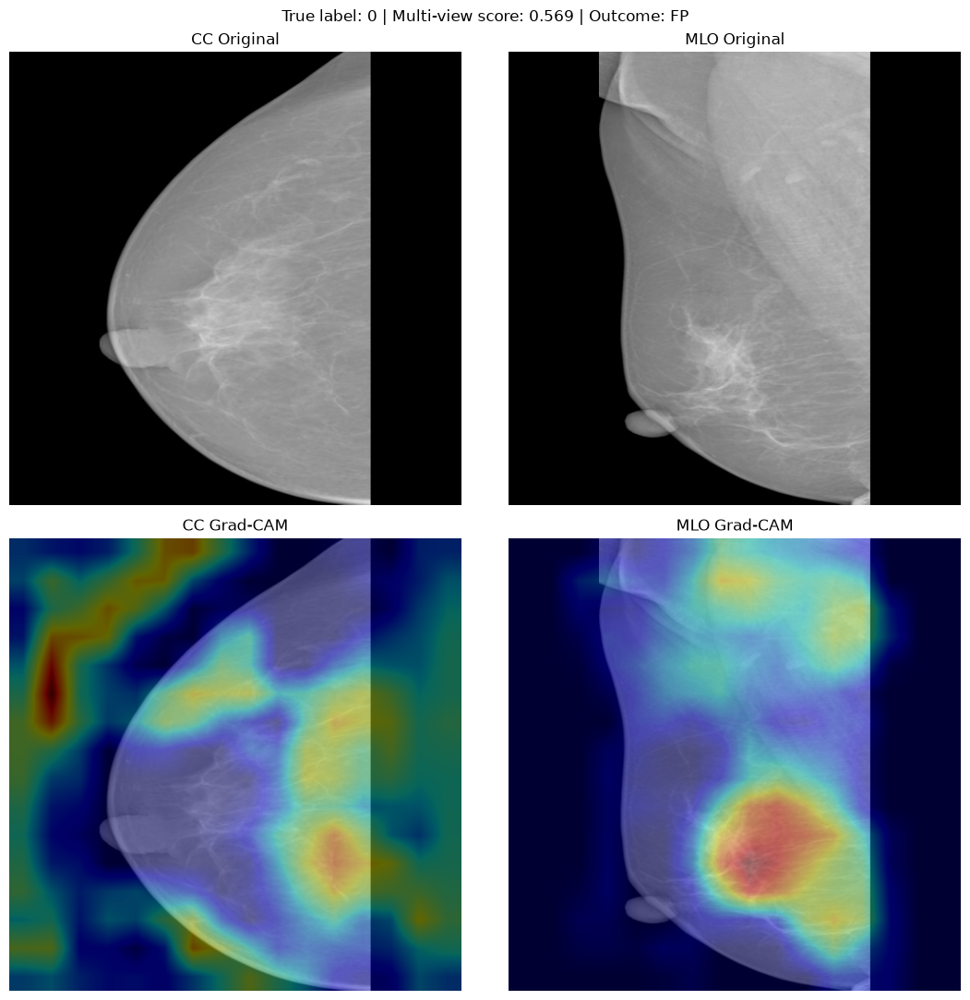

introduced: test row 59


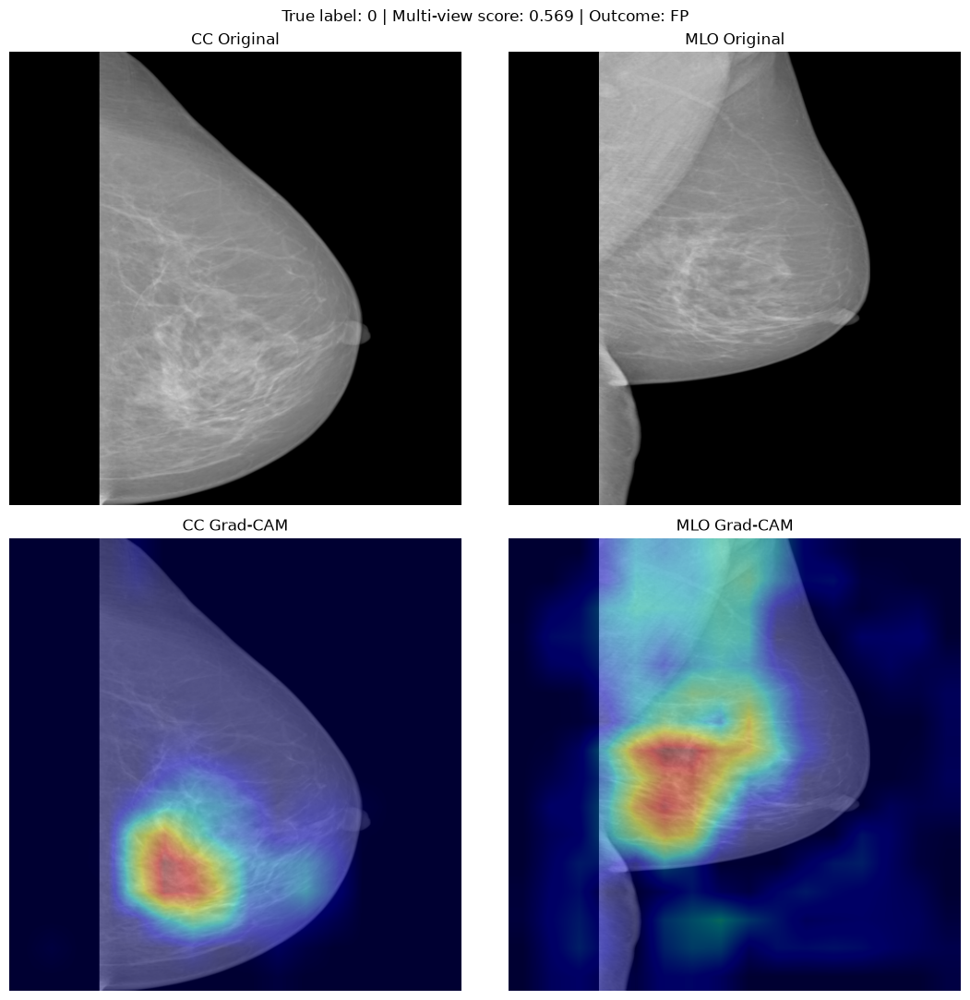

introduced: test row 60


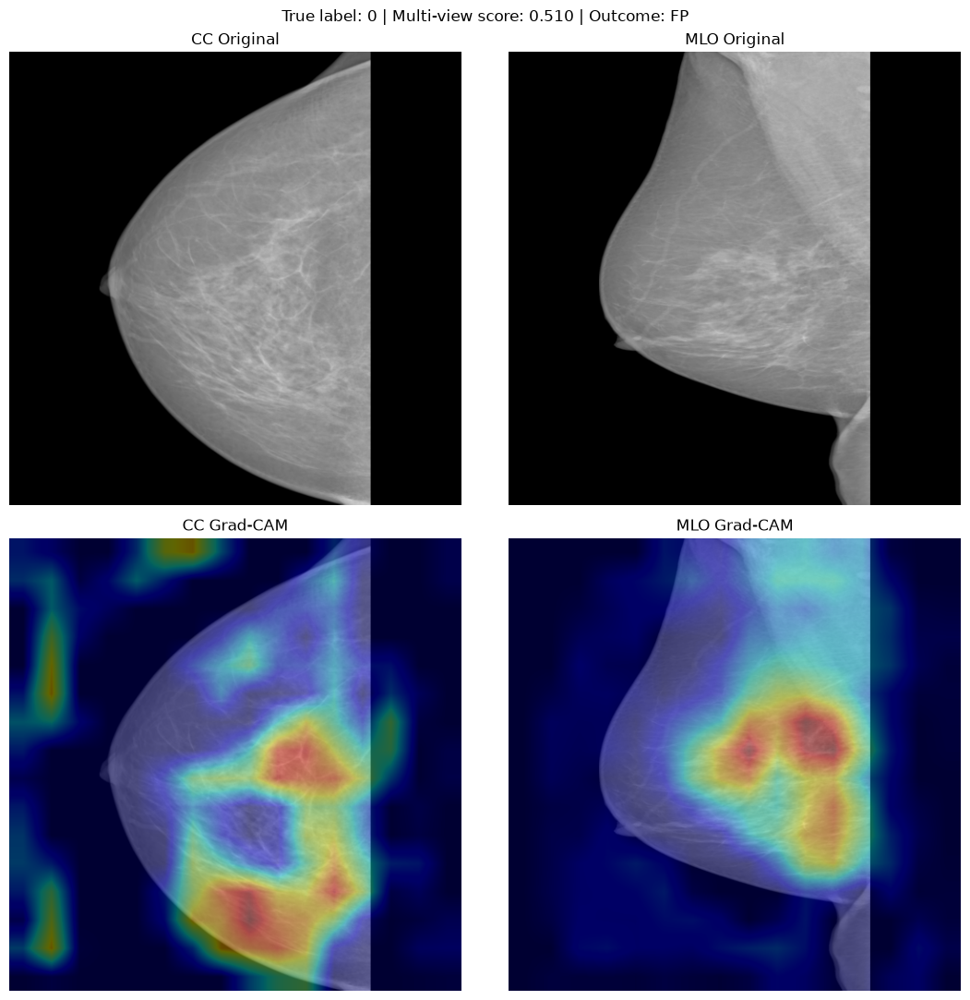

In [69]:
for group_name, cases in [
    ("corrected", corrected_cases.head(3)),
    ("introduced", introduced_errors.head(3))
]:

    for index, row in cases.iterrows():

        print(f"{group_name}: test row {index}")

        show_gradcam_case(
            row,
            gradcam,
            save_path=(
                GRADCAM_DIR
                / f"{group_name}_row{index}.png"
            )
        )

### Grad-CAM Analysis of Prediction Disagreements

Grad-CAM was additionally applied to three cases corrected by multi-view classification and three cases where multi-view introduced an error.

The heatmaps showed spatially distributed activations across both views, including responses within breast tissue and near image boundaries. Some examples exhibited different activation patterns between the CC and MLO encoders.

These observations suggest that combining two views changes the visual evidence available to the classifier, but the maps do not establish why an individual prediction was corrected or became incorrect.

A direct comparison with Grad-CAM from the single-view model and independent clinical annotations would be required for stronger conclusions.

In [70]:
gradcam.remove_hooks()

del gradcam
del gradcam_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Grad-CAM analysis completed.")
print("Figures saved to:", GRADCAM_DIR)

Grad-CAM analysis completed.
Figures saved to: c:\Users\Admin\Desktop\Projects\5_sem\DeepLearning\lab4\results\evaluation\gradcam


### Explainability Summary

Grad-CAM analysis was successfully performed for the multi-view ResNet50 using separate CC and MLO activation maps.

The visualizations revealed both localized and diffuse spatial responses. While several maps emphasized regions within breast tissue, others highlighted image boundaries and background areas, raising concerns about potential reliance on non-diagnostic visual features.

Differences between the two views were observed in both correct and incorrect predictions. However, the available evidence is insufficient to establish reliable lesion localization or clinical interpretability.

Overall, Grad-CAM provides useful qualitative insights into model behavior but also highlights limitations that must be considered before clinical application.

## 5.8	Final Results and Discussion

In [72]:
final_test_metrics = pd.read_csv(
    RESULTS_DIR / "test_metrics.csv"
)

metric_columns = [
    "AUROC", "AUPRC", "Sensitivity",
    "Specificity", "Precision", "F1"
]

final_summary = (
    final_test_metrics
    .groupby("Model")[metric_columns]
    .agg(["mean", "std"])
)

formatted_summary = pd.DataFrame(index=final_summary.index)

for metric in metric_columns:
    formatted_summary[metric] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(
            final_summary[(metric, "mean")],
            final_summary[(metric, "std")]
        )
    ]

display(formatted_summary)

formatted_summary.to_csv(
    RESULTS_DIR / "final_performance_summary.csv"
)

,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
Model,,,,,,
multi_view,0.8005 ± 0.0070,0.4555 ± 0.0072,0.5219 ± 0.1108,0.8999 ± 0.0662,0.2800 ± 0.1557,0.3328 ± 0.0810
single_view,0.7880 ± 0.0093,0.4307 ± 0.0279,0.5286 ± 0.0254,0.8969 ± 0.0083,0.2195 ± 0.0056,0.3100 ± 0.0013


In [73]:
paired_bootstrap_results = pd.read_csv(
    RESULTS_DIR / "paired_bootstrap_comparison.csv"
)

display(paired_bootstrap_results.round(4))

,Metric,Mean difference,CI lower,CI upper
0,AUROC,0.0125,-0.0163,0.0424
1,AUPRC,0.0248,-0.0067,0.0555


### Statistical Interpretation

The multi-view model achieved a mean test AUROC of 0.8005 compared with 0.7880 for the single-view model. Mean AUPRC increased from 0.4307 to 0.4555, corresponding to an improvement of approximately 0.0248.

However, the paired study-level bootstrap confidence intervals included zero for both AUROC (95% CI: −0.0163 to 0.0424) and AUPRC (95% CI: −0.0067 to 0.0555).

Therefore, although multi-view fusion showed a modest average improvement in discrimination, the evidence does not establish a statistically conclusive advantage under the current evaluation protocol. The observed improvement should be interpreted as promising but uncertain.

In [74]:
error_counts = pd.read_csv(
    RESULTS_DIR / "test_error_counts.csv"
)

seed42_errors = (
    error_counts[error_counts["Seed"] == 42]
    .set_index("Model")
)

display(seed42_errors[["TN", "FP", "FN", "TP"]])

,TN,FP,FN,TP
Model,,,,
single_view,1636,172,49,50
multi_view,1585,223,41,58


### Classification Error Analysis

At the predefined classification threshold of 0.5, the multi-view model with seed 42 identified 58 of 99 suspicious test cases, compared with 50 for the single-view model.

This reduced false negatives from 49 to 41 but increased false positives from 172 to 223. Furthermore, case-level comparison showed that multi-view fusion corrected 91 single-view errors while introducing 134 new errors.

These findings demonstrate a trade-off between detecting suspicious cases and incorrectly flagging low-suspicion cases. Higher threshold-independent discrimination does not necessarily translate into fewer classification errors at a fixed threshold.

### Ablation Study Findings

The ablation experiments demonstrated that loss function selection, image resolution, and data augmentation influenced classification performance.

Focal loss improved sensitivity and AUPRC compared with standard BCE in the loss-function comparison. Increasing image resolution from 224 × 224 to 512 × 512 produced a substantial improvement in validation AUPRC, from 0.1354 to 0.3903.

Data augmentation improved sensitivity and F1-score but reduced AUPRC, highlighting that improvements in threshold-dependent metrics do not necessarily correspond to better ranking performance.

These experiments informed the final model configurations. However, the effects should be interpreted within each ablation comparison because some training settings differed across experiments.

### Explainability and Clinical Limitations

Grad-CAM visualizations were generated separately for the CC and MLO encoders of the multi-view ResNet50.

The heatmaps showed both localized and diffuse activations, including responses within breast tissue and near image boundaries. These observations suggest that model predictions may depend on a combination of potentially relevant anatomical features and non-diagnostic image characteristics.

However, Grad-CAM does not provide validated lesion localization, and the clinical significance of the highlighted regions cannot be established without independent annotations.

Additional limitations include the relatively small number of positive test cases, variation across training seeds, possible dependence between observations, and the use of BI-RADS-derived suspicion labels rather than histopathologically confirmed malignancy.

The study evaluates classification of suspicious breast cases and should not be interpreted as a clinically validated breast cancer diagnosis system.

### Final Conclusion

This study investigated whether combining CC and MLO mammographic views improves breast-level classification compared with single-view analysis.

Three independent training runs per architecture were evaluated on a held-out test set containing 1,907 breast pairs, including 99 suspicious cases.

The multi-view ResNet50 achieved higher mean test AUROC (0.8005 versus 0.7880) and AUPRC (0.4555 versus 0.4307). Nevertheless, paired bootstrap confidence intervals included zero, and performance improvements were not consistent across all random seeds and classification metrics.

Error analysis revealed that multi-view fusion reduced some false negatives but introduced additional false positives at the default classification threshold. Grad-CAM further highlighted variability in the spatial features associated with model predictions.

Overall, the findings suggest that multi-view learning may provide additional information for mammography classification, but its advantage remains modest and uncertain. Further research should investigate patient-level generalization, threshold optimization, larger datasets, and clinically validated explainability methods before considering practical deployment.

In [75]:
final_metrics_export = (
    final_test_metrics
    .groupby("Model")[metric_columns]
    .agg(["mean", "std"])
)

final_metrics_export.columns = [
    f"{metric}_{stat}"
    for metric, stat in final_metrics_export.columns
]

final_metrics_export = final_metrics_export.reset_index()

final_metrics_export.to_csv(
    RESULTS_DIR / "final_report_metrics.csv",
    index=False
)

print("Final report metrics saved.")
display(final_metrics_export.round(4))

Final report metrics saved.


,Model,AUROC_mean,AUROC_std,AUPRC_mean,AUPRC_std,Sensitivity_mean,Sensitivity_std,Specificity_mean,Specificity_std,Precision_mean,Precision_std,F1_mean,F1_std
0,multi_view,0.8005,0.0070,0.4555,0.0072,0.5219,0.1108,0.8999,0.0662,0.2800,0.1557,0.3328,0.0810
1,single_view,0.7880,0.0093,0.4307,0.0279,0.5286,0.0254,0.8969,0.0083,0.2195,0.0056,0.3100,0.0013
